# Reproducing Martiny et al. (2026), *Genomic-to-space measurements reveal large-scale ocean nutrient stress*
*Sci. Adv.* 12, eaed8089 — doi:10.1126/sciadv.aed8089

This notebook rebuilds the paper's figures and headline numbers in Python. It follows the authors' own MATLAB/R
code (github.com/ljustick/genomic_to_space_nut_stress, Zenodo 10.5281/zenodo.15168175) step for step:

| Step | Authors' script | What it does |
|---|---|---|
| Pre-processing | `preprocess_LowLat_thetaPrime_v3_bathy.m` | 40.5°S–40.5°N; drop pixels with >25 % gaps; clip Θ′ to [0, 4]; fill gaps in time; 5-point lowess; clip again |
| Climatology | `global_geomean_figure_v5.m` | geometric mean of the 8-day series |
| Seasonal vs yearly variance | `ANOVA_analysis.m`, `ANOVA_*.m` | two-way ANOVA per pixel, factors = year and month |
| Modes | `EOF_variance.m` | linear detrend, EOF (8 modes), periodogram |
| Climate cycles | `climate_index_comparison.m` | lowess(30) on PC5–8, correlate with ONI and PDO |
| Trends | `longterm_SST_theta_overlay.m`, `trend_byRegion_wSST.m` | per-pixel linear trend (per year); regions by 50 m nitracline; 10⁴ bootstraps |
| SST vs Θ′ | `delta_SST_theta_plot.m` | correlate ANOVA month and year effects of SST and Θ′ |
| In situ | `random_forest_analysis_v2.R` | random forests on nutricline + genomic Ω biomarkers |

## Data

| File | Needed for | Status |
|---|---|---|
| `thetaPrime_MODIS.mat`, `thetaPrime_seawifs.mat` | everything satellite | **required** — Dryad doi:10.5061/dryad.f4qrfj71p |
| `ersstv5.nc` | SST fallback, computed ENSO/PDO fallback | downloaded automatically (xarray tutorial copy of NOAA ERSSTv5) |
| `oni.ascii.txt` | Fig. 3A with the official ONI | optional — NOAA CPC |
| `ersst.v5.pdo.dat` | Fig. 3D with the official PDO | optional — NOAA NCEI |
| `Dataset_S1.xlsx` (Gerace et al. 2025) | nitracline per 1° cell (sheet `WOD Means (no3=3)`): Fig. 4D regions, Fig. 1A, Fig. 2B | optional — Dryad doi:10.5061/dryad.v41ns1s4v |
| `woa23_all_n00_01.nc` | denser nitracline map for Fig. 1A / 2B (the paper's source for Fig. 2B) | optional — NOAA World Ocean Atlas 2023 |
| Zenodo 10.5281/zenodo.8064615: `data_insitu_v2_25-04.csv`, `sat_data*/genomic_OCmatchups_v3_medians_*.csv` | Fig. 1B–C, S2, S4, S5, S17 (in situ) | optional — the authors' data deposit |
| `SST_v2_lowlat.npz` (made by `shrink_sst.py` from the Zenodo `SST_v2_25-04.csv`), or the csv / csv.gz itself | MODIS SST for Fig. 4, S15, S16 | optional — the csv is very large; see `shrink_sst.py` |

Put the files in `DATA_DIR` (below). Any optional file that is missing is skipped and the notebook says what it
used instead. **Low Θ′ = more nutrient stress.**

In [1]:
# ============================== configuration ==============================
from pathlib import Path
DATA_DIR = Path(".")                      # folder holding the files listed above
OUT = Path("figures"); OUT.mkdir(exist_ok=True)

F = dict(
    modis=DATA_DIR / "thetaPrime_MODIS.mat",
    seawifs=DATA_DIR / "thetaPrime_seawifs.mat",
    ersst=DATA_DIR / "ersstv5.nc",
    oni=DATA_DIR / "oni.ascii.txt",
    pdo=DATA_DIR / "ersst.v5.pdo.dat",
    dataset_s1=DATA_DIR / "Dataset_S1.xlsx",
    woa=DATA_DIR / "woa23_all_n00_01.nc",
    zenodo=DATA_DIR / "zenodo_8064615",   # unzip the Zenodo deposit here
)
ERSST_URL = "https://raw.githubusercontent.com/pydata/xarray-data/master/ersstv5.nc"
N_BOOT = 10_000
SEED = 123

In [2]:
import datetime as dt
import glob
import re
import urllib.request
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display
from matplotlib.colors import ListedColormap, TwoSlopeNorm

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "savefig.bbox": "tight"})
C1, C2, C3, C4 = "#2a6fdb", "#e0732c", "#3a9e5c", "#9b59b6"
LAND, SEQ, DIV = "#d9d9d9", "GnBu", "RdBu"          # RdBu: red = lower Θ′ (more stress)
RES = {}                                             # reproduced numbers, collected for the summary table


def have(key):
    p = F[key]
    return p.exists()


def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=170)
    plt.show()


def mapax(ax, Z, title=None, cbar=None, fig=None, **kw):
    ax.set_facecolor(LAND)
    im = ax.pcolormesh(LON, LAT, Z, shading="nearest", rasterized=True, **kw)
    ax.set_xlim(-180, 180); ax.set_ylim(-40.5, 40.5); ax.set_aspect("equal")
    ax.set_xticks([-120, -60, 0, 60, 120]); ax.set_yticks([-40, -20, 0, 20, 40]); ax.tick_params(labelsize=6, length=2)
    for s in ax.spines.values():
        s.set_visible(True); s.set_linewidth(0.4)
    if title:
        ax.set_title(title, fontsize=8)
    if cbar is not None and fig is not None:
        cb = fig.colorbar(im, cax=ax.inset_axes([1.015, 0, 0.018, 1])); cb.set_label(cbar, fontsize=7)
        cb.ax.tick_params(labelsize=6)
    return im


def lowess_matlab(Y, span):
    """MATLAB smooth(y, span, 'lowess'): local linear fit, tricube weights, window shifted at the ends.
    Works on a vector or on each column of a 2-D array (no NaNs)."""
    Y = np.asarray(Y, float); vec = Y.ndim == 1
    Y = Y[:, None] if vec else Y
    n = Y.shape[0]; x = np.arange(n, dtype=float); h = span // 2; out = np.empty_like(Y)
    for i in range(n):
        lo = min(max(i - h, 0), n - span); idx = np.arange(lo, lo + span)
        d = np.abs(x[idx] - x[i]); w = (1 - (d / d.max()) ** 3) ** 3; xw = x[idx] - x[i]
        S0, S1, S2 = w.sum(), (w * xw).sum(), (w * xw ** 2).sum()
        out[i] = (S2 * (w[:, None] * Y[idx]).sum(0) - S1 * ((w * xw)[:, None] * Y[idx]).sum(0)) / (S0 * S2 - S1 ** 2)
    return out[:, 0] if vec else out


def pearson(a, b):
    a, b = np.ravel(a), np.ravel(b); ok = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[ok], b[ok])[0, 1]), int(ok.sum())


def boot_mean_ci(x, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), np.percentile(m, [2.5, 97.5])

## 1. Load Θ′ and apply the authors' pre-processing
`preprocess_LowLat_thetaPrime_v3_bathy.m`: keep 40.5°S–40.5°N, drop pixels missing in more than 224 of 897
composites (25 %), clip to [0, 4], fill gaps along time, smooth with a 5-point lowess, clip again.
Differences: the authors also masked shallow water with a bathymetry file (not published), and filled gaps with
`inpaint_nans`; linear interpolation is used here. The pixel count still matches their 22,468.

MODIS: 897 8-day composites, 2002-07-04 – 2022-01-01, grid 82x360, pixels kept 22468 (authors: 22,468)


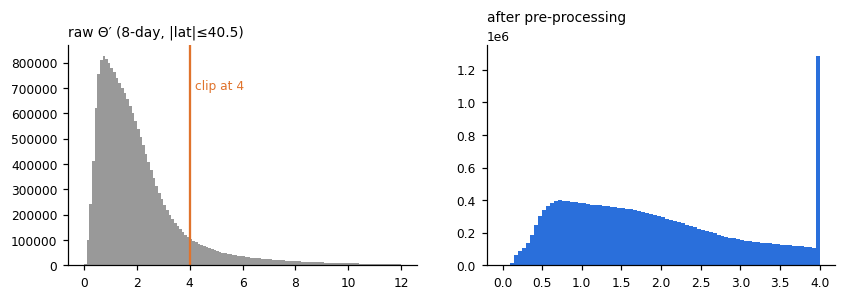

share of raw values > 4: 0.088;  raw max 110649


In [3]:
def load_theta(path):
    with h5py.File(path, "r") as f:
        var = [k for k in f.keys() if np.ndim(f[k]) == 3][0]
        c = np.array(f[var], dtype=np.float64)                      # h5py: TIME x LON x LAT
        lat = np.array(f["LAT"]).ravel(); lon = np.array(f["LON"]).ravel()
        yr = np.array(f["yr"]).ravel().astype(int); yd = np.array(f["yd"]).ravel().astype(int)
    band = np.abs(lat) <= 40.5
    c = np.transpose(c[:, :, band], (0, 2, 1))                      # TIME x LAT x LON
    la = lat[band]; o = np.argsort(la)
    return c[:, o, :], la[o], lon, yr, yd


def preprocess(c, max_missing_frac=0.25, nmax=4.0, span=5):
    T = c.shape[0]; D = c.reshape(T, -1).copy()
    nnan = np.isnan(D).sum(0)
    keep = (nnan <= int(max_missing_frac * T)) & (nnan < T)
    D[:, ~keep] = np.nan
    D = np.clip(D, 0, nmax)
    t = np.arange(T)
    for j in np.where(keep & (nnan > 0))[0]:
        ok = np.isfinite(D[:, j]); D[:, j] = np.interp(t, t[ok], D[ok, j])
    out = np.full_like(D, np.nan)
    out[:, keep] = np.clip(lowess_matlab(D[:, keep], span), 0, nmax)
    return out, keep


def dates_of(yr, yd):
    d = np.array([dt.date(y, 1, 1) + dt.timedelta(days=int(k) - 1) for y, k in zip(yr, yd)])
    return (d, np.array([x.year for x in d]), np.array([x.month for x in d]),
            np.array([x.toordinal() for x in d], float),
            np.array([x.year + (x.timetuple().tm_yday - 0.5) / 365.25 for x in d]))


raw, LAT, LON, yr, yd = load_theta(F["modis"])
TH, KEEP = preprocess(raw)
DATES, YEAR, MON, TNUM, TDEC = dates_of(yr, yd)
T, NY, NX = raw.shape[0], len(LAT), len(LON)
COSLAT = np.cos(np.deg2rad(np.repeat(LAT, NX)))
RES["n_pixels"] = int(KEEP.sum())
print(f"MODIS: {T} 8-day composites, {DATES[0]} – {DATES[-1]}, grid {NY}x{NX}, pixels kept {KEEP.sum()} (authors: 22,468)")
fig, ax = plt.subplots(1, 2, figsize=(9, 2.6))
ax[0].hist(raw[np.isfinite(raw)], bins=np.linspace(0, 12, 121), color="#999"); ax[0].set_title("raw Θ′ (8-day, |lat|≤40.5)")
ax[0].axvline(4, color=C2); ax[0].text(4.2, ax[0].get_ylim()[1] * 0.8, "clip at 4", color=C2)
ax[1].hist(TH[np.isfinite(TH)], bins=80, color=C1); ax[1].set_title("after pre-processing")
plt.show()
print(f"share of raw values > 4: {np.nanmean(raw > 4):.3f};  raw max {np.nanmax(raw):.0f}")
del raw

## 2. Ancillary data: SST and climate indices
SST: the paper used MODIS-Aqua SST (`SST_v2_25-04.csv` in the authors' Zenodo deposit). Without it, NOAA ERSSTv5
is interpolated to the same grid and dates. ONI/PDO: the official NOAA files if present, otherwise computed from
ERSSTv5 (ONI = 3-month running Niño3.4 anomaly vs 1991–2020; PDO = leading EOF of North Pacific SST anomalies
20–70°N with the global mean removed).

In [4]:
if not have("ersst"):
    print("downloading ERSSTv5 ...")
    urllib.request.urlretrieve(ERSST_URL, F["ersst"])
ERS = xr.open_dataset(F["ersst"])["sst"].sortby("lat")


def repair_coords(la, lo, rows, vals):
    """The authors' SST csv is a 180 x 360 grid flattened column by column (latitude fastest), but its longitude
    column was written as a repeated list, so lon does not belong to its row. Detect that and rebuild lon from the
    row number; choose the longitude ordering whose time-mean SST map best matches ERSSTv5."""
    LATD = np.arange(89.5, -90, -1)
    lo_step = np.diff(lo[:400]); la_step = np.diff(la[:400])
    tiled = rows is not None and np.all(np.isin(np.round(la, 1), LATD)) and np.mean(np.isclose(la_step, -1)) > 0.9 \
        and np.mean(np.isclose(lo_step, 1)) > 0.9
    if not tiled:
        return la, lo
    m = ERS.sel(time=slice("2003", "2021")).mean("time")
    m = m.assign_coords(lon=(((m.lon + 180) % 360) - 180)).sortby("lon")
    mean_sst = np.nanmean(vals, axis=1)

    def score(lo_try):
        ref = m.interp(lat=xr.DataArray(la), lon=xr.DataArray(lo_try), method="nearest").values
        ok = np.isfinite(ref) & np.isfinite(mean_sst) & (np.abs(la) <= 60)
        return np.corrcoef(ref[ok], mean_sst[ok])[0, 1] if ok.sum() > 100 else -1

    col = rows // 180
    candidates = {"as written in the file": lo,
                  "column-major, lon from -179.5": -179.5 + col,
                  "column-major, lon from 0.5": ((0.5 + col + 180) % 360) - 180,
                  "column-major, lon from 20.5 (authors' shifted grid)": ((20.5 + col + 180) % 360) - 180}
    scores = {k: score(v) for k, v in candidates.items()}
    best = max(scores, key=scores.get)
    print("SST csv coordinates: match with ERSSTv5 mean map (r):", {k: round(v, 3) for k, v in scores.items()})
    print("  -> using:", best)
    return la, candidates[best]


def read_8day_csv(path):
    """Authors' csv layout: first two rows = Year, Day; first two columns = Lat, Lon; cells = values.
    Also reads the compact .npz written by shrink_sst.py, and a transposed csv (time in rows)."""
    rows = None
    if str(path).endswith(".npz"):
        z = np.load(path)
        yrs, days, la, lo = z["year"], z["day"], z["lat"], z["lon"]
        rows = z["row"] if "row" in z.files else None
        vals = z["sst_centiC"].astype(float); vals[vals == -32768] = np.nan; vals /= 100   # pixels x time
    else:
        df = pd.read_csv(path, header=None)
        r0 = pd.to_numeric(df.iloc[0, 2:], errors="coerce").values
        if np.nanmin(r0) > 1990 and np.nanmax(r0) < 2030:            # time in columns (README layout)
            yrs, days = r0.astype(int), df.iloc[1, 2:].astype(int).values
            la, lo = df.iloc[2:, 0].astype(float).values, df.iloc[2:, 1].astype(float).values
            vals = df.iloc[2:, 2:].astype(float).values; rows = np.arange(len(la))
        else:                                                         # time in rows
            yrs, days = df.iloc[2:, 0].astype(int).values, df.iloc[2:, 1].astype(int).values
            la, lo = df.iloc[0, 2:].astype(float).values, df.iloc[1, 2:].astype(float).values
            vals = df.iloc[2:, 2:].astype(float).values.T
    la, lo = repair_coords(la, lo, rows, vals)
    grid = np.full((len(yrs), NY * NX), np.nan)
    ii = np.searchsorted(LAT, la); jj = np.searchsorted(LON, lo)
    okp = (ii < NY) & (jj < NX)
    okp[okp] &= (np.abs(LAT[ii[okp]] - la[okp]) < 0.01) & (np.abs(LON[jj[okp]] - lo[okp]) < 0.01)
    grid[:, (ii * NX + jj)[okp]] = vals[okp].T
    key = {(a, b): k for k, (a, b) in enumerate(zip(yrs, days))}
    out = np.full((T, NY * NX), np.nan)
    for t_, (a, b) in enumerate(zip(yr, yd)):
        if (a, b) in key:
            out[t_] = grid[key[(a, b)]]
    return out


sst_csv = sorted(glob.glob(str(DATA_DIR / "**" / "SST_v2*.npz"), recursive=True)) + \
          sorted(glob.glob(str(DATA_DIR / "**" / "SST_v2*.csv*"), recursive=True))
if sst_csv:
    try:
        SST8 = read_8day_csv(sst_csv[0]); SST_SRC = "MODIS-Aqua SST (authors' Zenodo csv)"
    except Exception as e:
        print("could not parse", sst_csv[0], "->", e); sst_csv = []
if not sst_csv:
    s = ERS.assign_coords(lon=(((ERS.lon + 180) % 360) - 180)).sortby("lon")
    s = xr.concat([s.isel(lon=-1).assign_coords(lon=s.lon[-1] - 360), s, s.isel(lon=0).assign_coords(lon=s.lon[0] + 360)], "lon")
    s = s.sel(time=slice("2002-06", None)).interp(lat=LAT, lon=LON)
    ym = s.time.dt.year.values * 12 + s.time.dt.month.values - 1
    k = np.array([np.argmin(np.abs(ym - (a * 12 + m - 1))) for a, m in zip(YEAR, MON)])
    SST8 = s.values.reshape(len(ym), -1)[k]; SST_SRC = "NOAA ERSSTv5 (2°, interpolated) — fallback"
SST8[:, ~KEEP] = np.nan


def fill_gaps(Z, max_missing_frac=0.25, span=5):
    """Same gap treatment the authors apply before their SST trend/ANOVA (DataLL_SST.mat):
    keep pixels missing <= 25% of composites, fill gaps along time, 5-point lowess."""
    T_ = Z.shape[0]; nnan = np.isnan(Z).sum(0)
    keep = (nnan <= int(max_missing_frac * T_)) & (nnan < T_)
    D = Z[:, keep].copy(); t = np.arange(T_)
    for j in np.where(np.isnan(D).any(0))[0]:
        ok = np.isfinite(D[:, j]); D[:, j] = np.interp(t, t[ok], D[ok, j])
    out = np.full_like(Z, np.nan); out[:, keep] = lowess_matlab(D, span)
    return out


if sst_csv:
    cov = np.isfinite(SST8[:, KEEP]).mean(0)
    print(f"MODIS SST coverage per pixel: median {np.median(cov):.0%}; pixels with >=75% coverage: {(cov >= 0.75).sum()} of {KEEP.sum()}")
    SST8 = fill_gaps(SST8)
print("SST source:", SST_SRC, "| pixels with usable SST:", int(np.isfinite(SST8).all(0).sum()))


def read_oni(path):
    seas = "DJF JFM FMA MAM AMJ MJJ JJA JAS ASO SON OND NDJ".split()
    rows = []
    for line in open(path):
        p = line.split()
        if len(p) >= 4 and p[0] in seas:
            rows.append((int(p[1]) + (seas.index(p[0]) + 0.5) / 12, float(p[3])))
    a = np.array(rows); return a[:, 0], a[:, 1]


def read_pdo(path):
    rows = []
    for line in open(path):
        p = line.split()
        if len(p) == 13 and re.fullmatch(r"\d{4}", p[0]):
            for m, v in enumerate(p[1:]):
                v = float(v)
                if abs(v) < 90:                     # NCEI marks missing months as 99.99 / -99.99
                    rows.append((int(p[0]) + (m + 0.5) / 12, v))
    a = np.array(rows); return a[:, 0], a[:, 1]


ty = ERS.time.dt.year.values + (ERS.time.dt.month.values - 0.5) / 12
anom = ERS.groupby("time.month") - ERS.sel(time=slice("1991", "2020")).groupby("time.month").mean()
if have("oni"):
    ONI_T, ONI = read_oni(F["oni"]); ONI_SRC = "NOAA CPC (official)"
else:
    n34 = anom.sel(lat=slice(-5, 5), lon=slice(190, 240))
    nino = n34.weighted(np.cos(np.deg2rad(n34.lat))).mean(("lat", "lon")).values
    ONI_T, ONI = ty, np.convolve(nino, np.ones(3) / 3, "same"); ONI_SRC = "computed from ERSSTv5 — fallback"
if have("pdo"):
    PDO_T, PDO = read_pdo(F["pdo"]); PDO_SRC = "NOAA NCEI (official)"
else:
    glob_ = anom.weighted(np.cos(np.deg2rad(anom.lat))).mean(("lat", "lon"))
    npac = (anom - glob_).sel(lat=slice(20, 70), lon=slice(110, 260))
    Yp = (npac * np.sqrt(np.cos(np.deg2rad(npac.lat)))).values.reshape(len(ty), -1)
    okc = np.isfinite(Yp).all(0); Yp = Yp[:, okc] - Yp[:, okc].mean(0)
    u, s_, _ = np.linalg.svd(Yp, full_matrices=False); pdo = (u[:, 0] - u[:, 0].mean()) / u[:, 0].std()
    ref = npac.sel(lat=40, lon=180, method="nearest").values
    PDO_T, PDO = ty, (-pdo if np.corrcoef(pdo, ref)[0, 1] > 0 else pdo); PDO_SRC = "computed from ERSSTv5 — fallback"
print("ONI:", ONI_SRC, "| PDO:", PDO_SRC)

downloading ERSSTv5 ...
SST csv coordinates: match with ERSSTv5 mean map (r): {'as written in the file': np.float64(0.932), 'column-major, lon from -179.5': np.float64(0.997), 'column-major, lon from 0.5': np.float64(0.914), "column-major, lon from 20.5 (authors' shifted grid)": np.float64(0.921)}
  -> using: column-major, lon from -179.5
MODIS SST coverage per pixel: median 100%; pixels with >=75% coverage: 22468 of 22468
SST source: MODIS-Aqua SST (authors' Zenodo csv) | pixels with usable SST: 22468
ONI: NOAA CPC (official) | PDO: NOAA NCEI (official)


## 3. Two-way ANOVA: seasonal vs year-to-year variance (authors' `anovan`)
Per pixel, Θ′ (and SST) = mean + year effect + month effect + error (main effects, type-III sums of squares,
effects sum to zero). The month effects are the monthly anomaly maps (Fig. 2C–F, S7), the year effects the yearly
anomaly maps (Fig. 3B/C/E/F, S14, S15); the SS fractions give Fig. S10; correlating SST and Θ′ effects gives S16.
Years 2002–2021 (the single January-2022 composite is left out).

In [5]:
def anova_year_month(Y, year, mon):
    years = np.unique(year)

    def eff(f, levels):
        X = np.zeros((len(f), len(levels) - 1))
        for k, l in enumerate(levels[:-1]):
            X[f == l, k] = 1
        X[f == levels[-1], :] = -1
        return X

    XY, XM, one = eff(year, years), eff(mon, np.arange(1, 13)), np.ones((len(year), 1))
    ok = np.isfinite(Y).all(0); Z = np.where(ok, Y, 0)

    def fit(X):
        b, *_ = np.linalg.lstsq(X, Z, rcond=None); return ((Z - X @ b) ** 2).sum(0), b

    sse_f, b = fit(np.hstack([one, XY, XM]))
    sse_noY, _ = fit(np.hstack([one, XM])); sse_noM, _ = fit(np.hstack([one, XY]))
    sst_ = ((Z - Z.mean(0)) ** 2).sum(0)
    ny = len(years)
    yeff = np.vstack([b[1:ny], -b[1:ny].sum(0)]); meff = np.vstack([b[ny:], -b[ny:].sum(0)])
    res = dict(years=years, frac_year=(sse_noY - sse_f) / sst_, frac_month=(sse_noM - sse_f) / sst_, yeff=yeff, meff=meff)
    for k in ("frac_year", "frac_month"):
        res[k] = np.where(ok, res[k], np.nan)
    for k in ("yeff", "meff"):
        res[k] = np.where(ok, res[k], np.nan)
    return res


def to_map(v):
    out = np.full(NY * NX, np.nan); out[KEEP] = v; return out.reshape(NY, NX)


use = YEAR <= 2021
AN = anova_year_month(TH[use][:, KEEP], YEAR[use], MON[use])
ANS = anova_year_month(SST8[use][:, KEEP], YEAR[use], MON[use])
MEFF = np.stack([to_map(AN["meff"][k]) for k in range(12)])            # 12 x lat x lon
YEFF = np.stack([to_map(AN["yeff"][k]) for k in range(len(AN["years"]))])
MEFF_S = np.stack([to_map(ANS["meff"][k]) for k in range(12)])
YEFF_S = np.stack([to_map(ANS["yeff"][k]) for k in range(len(ANS["years"]))])
FRAC_Y, FRAC_M = to_map(AN["frac_year"]), to_map(AN["frac_month"])
YEARS = list(AN["years"])
RES["anova_median_seasonal"] = float(np.nanmedian(FRAC_M)); RES["anova_median_annual"] = float(np.nanmedian(FRAC_Y))
print(f"median variance fraction: seasonal {RES['anova_median_seasonal']:.2f}, year-to-year {RES['anova_median_annual']:.2f}")

median variance fraction: seasonal 0.53, year-to-year 0.06


## 4. Remaining computations (figures follow in section 5)

In [6]:
from scipy import stats

GEO = np.exp(np.nanmean(np.log(np.clip(TH, 1e-3, None)), axis=0)).reshape(NY, NX)
GEO[~KEEP.reshape(NY, NX)] = np.nan


def nitracline_from_woa(path, thr=3.0):
    ds = xr.open_dataset(path, decode_times=False)
    n = ds["n_an"].isel(time=0) if "time" in ds["n_an"].dims else ds["n_an"]
    n = n.sel(lat=slice(-41, 41)).interp(lat=LAT, lon=LON, method="nearest")
    z = n.depth.values; v = n.values
    out = np.full(v.shape[1:], np.nan); out[v[0] >= thr] = 0.0
    for k in range(1, len(z)):
        a, b = v[k - 1], v[k]; hit = np.isnan(out) & (a < thr) & (b >= thr)
        out[hit] = z[k - 1] + (thr - a[hit]) * (z[k] - z[k - 1]) / (b[hit] - a[hit])
    return out


def nitracline_from_s1(path, sheet="WOD Means (no3=3)"):
    """Gerace et al. 2025 Dataset S1. The authors' trend script reads 'Dataset S1_WOD' (lat_degN, lon_degE, Zno3_m)
    and shifts lon +0.5, lat -0.5 onto the 1-degree cell centres."""
    xl = pd.read_excel(path, sheet_name=None)
    if sheet not in xl:
        cand = [k for k, d in xl.items() if {"lat_degN", "lon_degE", "Zno3_m"} <= set(d.columns)]
        print(f"sheet '{sheet}' not found; using '{cand[0]}'"); sheet = cand[0]
    d = xl[sheet].dropna(subset=["Zno3_m"])
    la = d["lat_degN"].values - 0.5; lo = ((d["lon_degE"].values + 0.5 + 180) % 360) - 180
    out = np.full((NY, NX), np.nan); ii = np.searchsorted(LAT, la - 1e-6); jj = np.searchsorted(LON, lo - 1e-6)
    ok = (ii < NY) & (jj < NX)
    ok[ok] &= (np.abs(LAT[ii[ok]] - la[ok]) < 0.01) & (np.abs(LON[jj[ok]] - lo[ok]) < 0.01)
    acc = pd.DataFrame({"k": ii[ok] * NX + jj[ok], "z": d["Zno3_m"].values[ok]}).groupby("k")["z"].mean()
    out.ravel()[acc.index.values] = acc.values
    return out, sheet


Z_S1, S1_SHEET = nitracline_from_s1(F["dataset_s1"]) if have("dataset_s1") else (None, None)
if have("woa"):
    ZNO3, ZNO3_SRC = nitracline_from_woa(F["woa"]), "WOA 2023"
elif Z_S1 is not None:
    ZNO3, ZNO3_SRC = Z_S1, f"Gerace et al. 2025, {S1_SHEET}"
else:
    ZNO3, ZNO3_SRC = None, None
print("nitracline source:", ZNO3_SRC)

boxes = {"S Pacific gyre": (-35, -15, -140, -90), "S Indian gyre": (-35, -15, 60, 100), "S Atlantic gyre": (-35, -15, -30, 5),
         "N Pacific gyre": (15, 35, -180, -140), "N Atlantic gyre": (15, 35, -70, -30)}
for k, (a, b, c, d) in boxes.items():
    m = (LAT[:, None] >= a) & (LAT[:, None] <= b) & (LON[None, :] >= c) & (LON[None, :] <= d) & np.isfinite(GEO)
    RES[f"theta_{k}"] = float(np.exp(np.log(GEO[m]).mean()))
if ZNO3 is not None:
    ok = np.isfinite(GEO) & np.isfinite(ZNO3)
    RES["fig1A_r"], RES["fig1A_n"] = pearson(ZNO3[ok], GEO[ok])

# ---- EOF (EOF_variance.m): linear detrend, EOF of the 8-day series, no area weighting
X = TH[:, KEEP].copy()
tc = TNUM - TNUM.mean()
X -= X.mean(0); X -= np.outer(tc, (tc @ X) / (tc @ tc))
U, Sv, Vt = np.linalg.svd(X, full_matrices=False)
VAR = 100 * Sv ** 2 / (Sv ** 2).sum()
NM = 8
PCS = U[:, :NM] * Sv[:NM]          # projection on unit-norm EOFs (CDT convention)
LOADS = Vt[:NM].copy()             # unit-norm spatial patterns (S12)
RES["eof_var"] = VAR[:NM].round(2).tolist()
RES["eof_1_4"], RES["eof_5_8"], RES["eof_1_8"] = float(VAR[:4].sum()), float(VAR[4:8].sum()), float(VAR[:8].sum())
print("variance %:", np.round(VAR[:NM], 2), f"| PC1-4 {VAR[:4].sum():.1f}  PC5-8 {VAR[4:8].sum():.1f}  (paper 59.4 / 4.2)")

oni_i, pdo_i = np.interp(TDEC, ONI_T, ONI), np.interp(TDEC, PDO_T, PDO)
latk, lonk = np.repeat(LAT, NX)[KEEP], np.tile(LON, NY)[KEEP]


def box_mean(k, la0, la1, lo0, lo1):
    m = (latk >= la0) & (latk <= la1) & (lonk >= lo0) & (lonk <= lo1); return LOADS[k][m].mean()


# signs are arbitrary: orient each mode like the published Fig. S12 / Fig. 3
ref_sign = {0: -np.sign(box_mean(0, 15, 40, -180, 180)),          # PC1: northern subtropics negative
            1: np.sign(box_mean(1, -5, 5, -10, 5)),               # PC2: equatorial Atlantic positive
            2: -np.sign(box_mean(2, 0, 10, -140, -100)),          # PC3: NE equatorial Pacific negative
            3: np.sign(box_mean(3, 15, 25, 140, 180)),            # PC4: 20N west-central Pacific positive
            6: -np.sign(box_mean(6, 5, 20, 50, 70)),              # PC7: Arabian Sea negative
            7: np.sign(box_mean(7, 3, 10, -170, -130))}           # PC8: 5-10N central Pacific positive
YY = np.stack([lowess_matlab(PCS[:, k], 30) for k in range(NM)], 1)      # lowess(30) as in climate_index_comparison.m
ref_sign[4] = np.sign(np.corrcoef(YY[:, 4], oni_i)[0, 1]); ref_sign[5] = np.sign(np.corrcoef(YY[:, 5], pdo_i)[0, 1])
for k, s_ in ref_sign.items():
    PCS[:, k] *= s_; YY[:, k] *= s_; LOADS[k] *= s_
R5 = stats.pearsonr(YY[:, 4], oni_i); R6 = stats.pearsonr(YY[:, 5], pdo_i)
RES["r_PC5_ONI"], RES["p_PC5_ONI"] = float(R5[0]), float(R5[1]); RES["r_PC6_PDO"], RES["p_PC6_PDO"] = float(R6[0]), float(R6[1])
display(pd.DataFrame({"r with ONI": [pearson(YY[:, k], oni_i)[0] for k in range(4, 8)],
                      "r with PDO": [pearson(YY[:, k], pdo_i)[0] for k in range(4, 8)]}, index=[f"PC{k}" for k in range(5, 9)]).round(2))

# ---- SST vs Θ′ (delta_SST_theta_plot.m)
RES["S16_r_seasonal"], _ = pearson(MEFF_S, MEFF); RES["S16_r_annual"], _ = pearson(YEFF_S, YEFF)

# ---- trends (longterm_SST_theta_overlay.m, trend_byRegion_wSST.m)
def trend_per_year(Z):
    ok = np.isfinite(Z); out = np.full(Z.shape[1], np.nan); full = ok.all(0)
    if full.any():
        Zf = Z[:, full]; out[full] = 365.25 * (tc @ (Zf - Zf.mean(0))) / (tc @ tc)
    for j in np.where(~full & (ok.sum(0) > 0.7 * T))[0]:
        m = ok[:, j]; t_ = TNUM[m] - TNUM[m].mean(); out[j] = 365.25 * (t_ @ (Z[m, j] - Z[m, j].mean())) / (t_ @ t_)
    return out


TR_TH = to_map(trend_per_year(TH[:, KEEP])); TR_SST = to_map(trend_per_year(SST8[:, KEEP]))
okt = np.isfinite(TR_TH) & np.isfinite(TR_SST); W = COSLAT.reshape(NY, NX)
RES.update(trend_theta_median=float(np.nanmedian(TR_TH)), trend_sst_median=float(np.nanmedian(TR_SST[okt])),
           frac_area_sst_up=float(W[okt & (TR_SST > 0)].sum() / W[okt].sum()),
           frac_area_theta_down=float(W[np.isfinite(TR_TH) & (TR_TH < 0)].sum() / W[np.isfinite(TR_TH)].sum()))
if Z_S1 is not None:
    ZCELL, REGIME_SRC = Z_S1, f"Gerace et al. 2025 Dataset S1, {S1_SHEET}"
elif ZNO3 is not None:
    ZCELL, REGIME_SRC = ZNO3, f"{ZNO3_SRC} (approximation of Dataset S1)"
else:
    ZCELL, REGIME_SRC = None, "PROXY: Θ′ below median (add Dataset_S1.xlsx)"
low_nut = (ZCELL > 50) if ZCELL is not None else (GEO < np.nanmedian(GEO))
valid_reg = np.isfinite(ZCELL) if ZCELL is not None else np.isfinite(GEO)
nh, sh_ = LAT[:, None] > 0, LAT[:, None] < 0
regions = {"All": np.ones_like(GEO, bool), "All (lowNut)": low_nut, "All (highNut)": ~low_nut,
           "NHemi (lowNut)": nh & low_nut, "NHemi (highNut)": nh & ~low_nut,
           "SHemi (lowNut)": sh_ & low_nut, "SHemi (highNut)": sh_ & ~low_nut}
rows = []
for nm, m in regions.items():
    m = m & okt & valid_reg
    mt, ct = boot_mean_ci(TR_TH[m]); ms, cs = boot_mean_ci(TR_SST[m])
    rows.append(dict(region=nm, n=int(m.sum()), theta_x10=10 * mt, theta_lo=10 * ct[0], theta_hi=10 * ct[1], sst=ms, sst_lo=cs[0], sst_hi=cs[1]))
REG = pd.DataFrame(rows).set_index("region"); RES["regions"] = REG
print("regions:", REGIME_SRC); display(REG.round(4))

# ---- SeaWiFS (same pre-processing), 2003-2007 overlap
if have("seawifs"):
    rs_, _, _, yr_s, yd_s = load_theta(F["seawifs"]); THs, KEEPs = preprocess(rs_); del rs_
    ks = {(a, b): i for i, (a, b) in enumerate(zip(yr_s, yd_s))}
    pairs = np.array([(i, ks[(a, b)]) for i, (a, b) in enumerate(zip(yr, yd)) if (a, b) in ks and 2003 <= a <= 2007])
    A_, B_ = TH[pairs[:, 0]], THs[pairs[:, 1]]; both = np.isfinite(A_) & np.isfinite(B_)
    A2, B2 = np.where(both, A_, np.nan), np.where(both, B_, np.nan)
    RES["S6_r_points"] = pearson(A_[both], B_[both])[0]; RES["S6_r_meanmap"] = pearson(np.nanmean(A2, 0), np.nanmean(B2, 0))[0]
    yrs_c = YEAR[pairs[:, 0]]
    S6_DEV = {nm: np.stack([np.nanmean(Z[yrs_c == y], 0) for y in range(2003, 2008)]) - np.nanmean(Z, 0) for nm, Z in [("SeaWiFS", B2), ("MODIS", A2)]}
    S6_MEAN = {"SeaWiFS": np.nanmean(B2, 0), "MODIS": np.nanmean(A2, 0)}
    RES["S6_r_annualdev"] = pearson(S6_DEV["MODIS"], S6_DEV["SeaWiFS"])[0]
    print({k: round(v, 3) for k, v in RES.items() if k.startswith("S6")})

nitracline source: WOA 2023
variance %: [43.86  7.19  5.45  1.97  1.42  0.99  0.91  0.83] | PC1-4 58.5  PC5-8 4.1  (paper 59.4 / 4.2)


,r with ONI,r with PDO
PC5,0.83,0.49
PC6,0.37,0.62
PC7,-0.02,-0.41
PC8,0.13,-0.16


regions: Gerace et al. 2025 Dataset S1, WOD Means (no3=3)


,n,theta_x10,theta_lo,theta_hi,sst,sst_lo,sst_hi
region,,,,,,,
All,8466,-0.0099,-0.0119,-0.0079,0.0233,0.0229,0.0237
All (lowNut),6560,-0.0084,-0.0107,-0.0061,0.0227,0.0223,0.0231
All (highNut),1906,-0.0148,-0.0187,-0.0109,0.0254,0.0244,0.0264
NHemi (lowNut),3325,-0.0423,-0.0453,-0.0391,0.0257,0.0250,0.0263
NHemi (highNut),971,-0.0240,-0.0298,-0.0182,0.0312,0.0296,0.0329
SHemi (lowNut),3235,0.0263,0.0233,0.0293,0.0197,0.0192,0.0202
SHemi (highNut),935,-0.0052,-0.0104,-0.0000,0.0193,0.0184,0.0202


{'S6_r_points': 0.894, 'S6_r_meanmap': 0.979, 'S6_r_annualdev': 0.751}


### In situ analyses (`random_forest_analysis_v2.R`, needs the authors' Zenodo tables)
scikit-learn port: 500 trees, mtry = p/3, out-of-bag R², seed 123. In the authors' script the list of match-up
tables starts with the 1° file instead of the 1-pixel file (`list(sat_data_1d, sat_data_3p, ...)`), so their "1P"
column of S4 repeats "1x1D"; here the 1-pixel file is used.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import partial_dependence

COLS = dict(nutricline="insitu_and_woa_nutricline", NH="Omega_N_High", NM="Omega_N_Med", PH="Omega_P_High",
            PM="Omega_P_Med", FeH="Omega_Fe_High", FeM="Omega_Fe_Med", sst="SST_underway",
            no3="nitrate_concentration", po4="phosphate_concentration", lat="LatitudeDegN", cruise="Cruise")
insitu_f = sorted(glob.glob(str(F["zenodo"] / "**" / "data_insitu*.csv"), recursive=True))
sat_f = {s: sorted(glob.glob(str(F["zenodo"] / "**" / f"genomic_OCmatchups*_{s}.csv"), recursive=True)) for s in ["1p", "3p", "5p", "1d", "2d", "5d"]}
HAVE_INSITU = bool(insitu_f) and all(sat_f.values())


def rf_r2(Xd, y, seed=SEED):
    p = Xd.shape[1]
    rf = RandomForestRegressor(n_estimators=500, max_features=max(1, p // 3), min_samples_leaf=5, oob_score=True,
                               random_state=seed, n_jobs=-1).fit(Xd, y)
    return 1 - np.mean((y - rf.oob_prediction_) ** 2) / np.var(y), rf, rf.oob_prediction_


if HAVE_INSITU:
    INS = pd.read_csv(insitu_f[0])
    SAT = {}
    for s, v in sat_f.items():
        d = pd.read_csv(v[0]).select_dtypes("number")
        SAT[s] = d.iloc[:, -15:] if d.shape[1] != 15 else d
    feats = [COLS[k] for k in ["nutricline", "PH", "NH", "NM", "FeH", "FeM"]]          # as in the R script
    S4_GRID = np.full((15, 6), np.nan)
    for j, s in enumerate(["1p", "3p", "5p", "1d", "2d", "5d"]):
        for i in range(15):
            y = SAT[s].iloc[:, i].values.astype(float); m = np.isfinite(y) & INS[feats].notna().all(1).values
            S4_GRID[i, j] = 100 * rf_r2(INS.loc[m, feats].values, y[m])[0]
    TH20 = SAT["2d"].iloc[:, 9].values.astype(float)                                    # 2x2 degree, ±20 days
    M20 = np.isfinite(TH20) & INS[feats].notna().all(1).values
    r2_n, _, pr_n = rf_r2(INS.loc[M20, [COLS["nutricline"]]].values, TH20[M20])
    r2_f, rf_full, pr_f = rf_r2(INS.loc[M20, feats].values, TH20[M20])
    RES["fig1B_R2_nutricline"], RES["fig1B_R2_full"] = r2_n, r2_f
    # Fig. 1C: partial dependence, model with all six biomarkers; effect = PD(90th pct) - PD(10th pct)
    feats_c = [COLS[k] for k in ["nutricline", "NH", "NM", "PH", "PM", "FeH", "FeM"]]
    _, rf_c, _ = rf_r2(INS.loc[M20, feats_c].values, TH20[M20])
    PD_EFF = {}
    for k in ["NH", "NM", "PH", "PM", "FeH", "FeM"]:
        i = feats_c.index(COLS[k]); pdp = partial_dependence(rf_c, INS.loc[M20, feats_c].values, [i], kind="average", grid_resolution=50)
        g, a = pdp["grid_values"][0], pdp["average"][0]; q = np.percentile(INS.loc[M20, COLS[k]], [10, 90])
        PD_EFF[k] = float(np.interp(q[1], g, a) - np.interp(q[0], g, a))
    RES["fig1C"] = PD_EFF
    RES_N, RES_F = TH20[M20] - pr_n, TH20[M20] - pr_f
    S2_COLS = [COLS[k] for k in ["nutricline", "sst", "no3", "po4", "NH", "NM", "PH", "PM", "FeH", "FeM"]]
    S2_STATS = []
    for c in S2_COLS:
        ok_ = np.isfinite(INS[c].values) & np.isfinite(TH20)
        S2_STATS.append(stats.pearsonr(INS[c].values[ok_], TH20[ok_]))
    print("RF R²: nutricline", round(r2_n, 3), "| + biomarkers", round(r2_f, 3), "| Fig1C effects", {k: round(v, 2) for k, v in PD_EFF.items()})
else:
    print("In situ files not found: Fig. 1B-C, S2/S4 recomputation, S5 and S17 use published values or are skipped.")

RF R²: nutricline 0.267 | + biomarkers 0.514 | Fig1C effects {'NH': -0.57, 'NM': -0.21, 'PH': 0.31, 'PM': 0.08, 'FeH': 0.34, 'FeM': -0.1}


## 5. Figures in the paper's style
Pacific-centred maps (20°E–20°E) with white land and no coastlines; reversed Spectral for Θ′, Spectral for the
nitracline, cmocean *balance* for anomalies and trends (red = higher Θ′ = less stress), inferno for variance.

In [8]:
import cmocean
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
from matplotlib.colors import LinearSegmentedColormap

BAL, SPEC, SPEC_R = cmocean.cm.balance, plt.get_cmap("Spectral"), plt.get_cmap("Spectral_r")
PARULA = LinearSegmentedColormap.from_list("parula", ["#352a87", "#0363e1", "#1485d4", "#06a7c6", "#38b99e",
                                                      "#92bf73", "#d9ba56", "#fcce2e", "#f9fb0e"])
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 11, "axes.titlelocation": "left",
                     "axes.spines.top": True, "axes.spines.right": True, "axes.linewidth": 0.7,
                     "xtick.direction": "in", "ytick.direction": "in", "xtick.major.size": 3, "ytick.major.size": 3,
                     "axes.facecolor": "white", "figure.facecolor": "white"})
PAC = np.r_[np.where(LON >= 20)[0], np.where(LON < 20)[0]]
LONP = np.where(LON < 20, LON + 360, LON)[PAC]
XT, XTL = [45, 90, 135, 180, 225, 270, 315, 360], ["45°E", "90°E", "135°E", "180°E", "135°W", "90°W", "45°W", "0°"]
XT4, XTL4 = [90, 180, 270, 360], ["90°E", "180°E", "90°W", "0°"]


def pmap(ax, Z, cmap, vmin, vmax, xticks="all", yticks="deg", title=None, tsize=11):
    """Pacific-centred map in the paper's style."""
    im = ax.pcolormesh(LONP, LAT, Z[:, PAC], cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest", rasterized=True)
    ax.set_xlim(20, 380); ax.set_ylim(-40.5, 40.5); ax.set_aspect("auto")
    if xticks == "all":
        ax.set_xticks(XT); ax.set_xticklabels(XTL)
    elif xticks == "four":
        ax.set_xticks(XT4); ax.set_xticklabels(XTL4)
    else:
        ax.set_xticks(XT if xticks == "ticks" else XT4); ax.set_xticklabels([])
    if yticks == "deg":
        ax.set_yticks([-40, -20, 0, 20, 40]); ax.set_yticklabels(["40°S", "20°S", "0°", "20°N", "40°N"])
    elif yticks == "num":
        ax.set_yticks([-40, -20, 0, 20, 40])
    else:
        ax.set_yticks([-40, -20, 0, 20, 40]); ax.set_yticklabels([])
    if title:
        ax.set_title(title, fontsize=tsize)
    return im


def plabel(ax, s, x=-0.06, y=1.04, size=12):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=size, fontweight="bold", va="bottom", ha="right")

### Fig. 1 — Environmental controls on Θ′

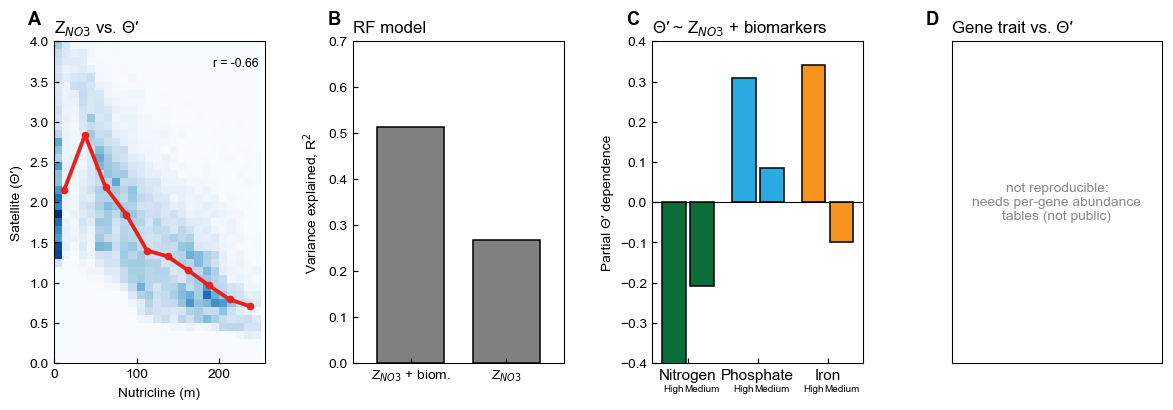

In [9]:
fig = plt.figure(figsize=(13, 3.8))
gs = fig.add_gridspec(1, 4, wspace=0.42)
ax = fig.add_subplot(gs[0])
if ZNO3 is not None:
    ok = np.isfinite(GEO) & np.isfinite(ZNO3)
    H, xe, ye = np.histogram2d(ZNO3[ok], GEO[ok], bins=[np.arange(0, 251, 10), np.arange(0, 4.01, 0.1)])
    ax.pcolormesh(xe, ye, H.T, cmap="Blues", shading="flat", rasterized=True)
    zb = np.arange(0, 250, 25); med = [np.median(GEO[ok][(ZNO3[ok] >= a) & (ZNO3[ok] < a + 25)]) for a in zb]
    ax.plot(zb + 12.5, med, "-o", color="#e8211b", lw=2.5, ms=4)
    ax.text(0.97, 0.95, f"r = {RES['fig1A_r']:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=8)
ax.set_xlim(0, 255); ax.set_ylim(0, 4); ax.set_xlabel("Nutricline (m)"); ax.set_ylabel("Satellite (Θ′)")
ax.set_title("Z$_{NO3}$ vs. Θ′"); plabel(ax, "A")
ax = fig.add_subplot(gs[1])
if HAVE_INSITU:
    ax.bar([0, 1], [r2_f, r2_n], color="#808080", edgecolor="k", width=0.7)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Z$_{NO3}$ + biom.", "Z$_{NO3}$"]); ax.set_xlim(-0.6, 1.6)
ax.set_ylim(0, 0.7); ax.set_ylabel("Variance explained, R$^2$"); ax.set_title("RF model"); plabel(ax, "B")
ax = fig.add_subplot(gs[2])
if HAVE_INSITU:
    pos = [0, 1, 2.5, 3.5, 5, 6]; cols = ["#0b6e3a", "#0b6e3a", "#29abe2", "#29abe2", "#f7941d", "#f7941d"]
    ax.bar(pos, [PD_EFF[k] for k in ["NH", "NM", "PH", "PM", "FeH", "FeM"]], color=cols, edgecolor="k", width=0.85)
    ax.set_xticks([0.5, 3, 5.5]); ax.set_xticklabels(["Nitrogen", "Phosphate", "Iron"], fontsize=10)
    for p_, t_ in zip(pos, ["High", "Medium"] * 3):
        ax.text(p_, -0.47, t_, ha="center", fontsize=6.5, transform=ax.transData)
ax.axhline(0, color="k", lw=0.7); ax.set_ylim(-0.4, 0.4); ax.set_ylabel("Partial Θ′ dependence")
ax.set_title("Θ′ ~ Z$_{NO3}$ + biomarkers"); plabel(ax, "C")
ax = fig.add_subplot(gs[3]); ax.set_title("Gene trait vs. Θ′"); plabel(ax, "D")
ax.text(0.5, 0.5, "not reproducible:\nneeds per-gene abundance\ntables (not public)", ha="center", va="center", color="#888", transform=ax.transAxes)
ax.set_xticks([]); ax.set_yticks([])
save(fig, "Fig1")

### Fig. 2 — Climatological nutrient stress

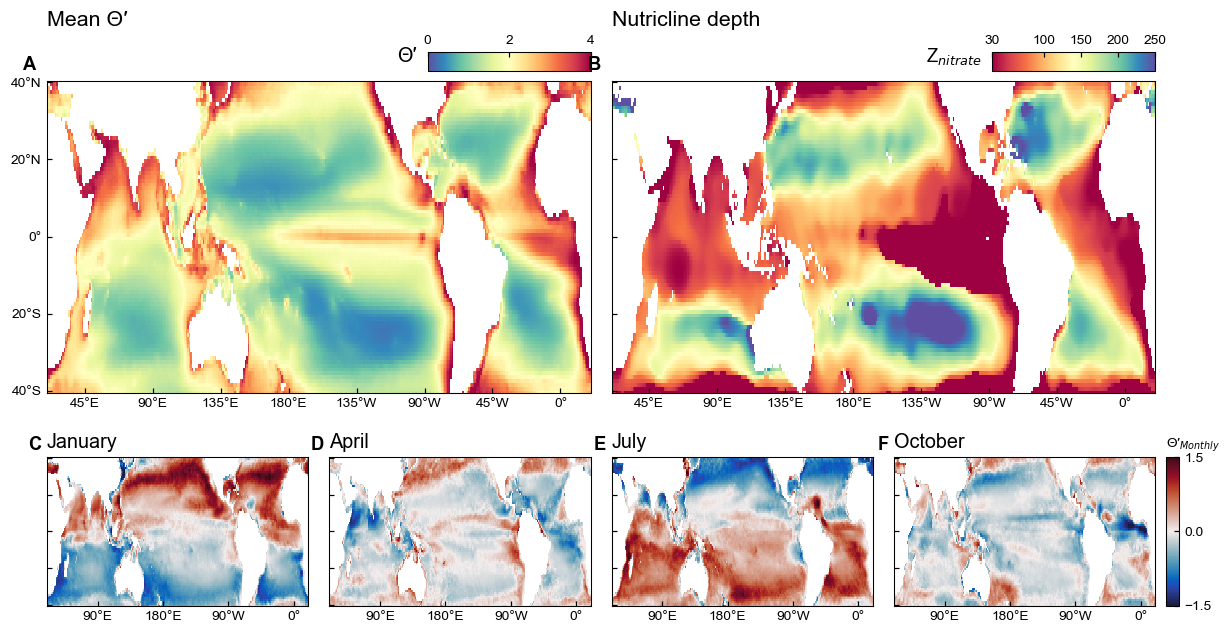

In [10]:
fig = plt.figure(figsize=(13, 6.2))
gs = fig.add_gridspec(2, 4, height_ratios=[2.1, 1], hspace=0.28, wspace=0.08)
ax = fig.add_subplot(gs[0, :2]); im = pmap(ax, GEO, SPEC_R, 0, 4, title="Mean Θ′", tsize=14); plabel(ax, "A", -0.02, 1.02)
cb = fig.colorbar(im, cax=ax.inset_axes([0.7, 1.03, 0.3, 0.06]), orientation="horizontal"); cb.ax.xaxis.set_ticks_position("top")
ax.text(0.68, 1.06, "Θ′", transform=ax.transAxes, ha="right", fontsize=13)
ax = fig.add_subplot(gs[0, 2:])
if ZNO3 is not None:
    im = pmap(ax, np.where(np.isfinite(GEO), ZNO3, np.nan), SPEC, 30, 250, yticks="none", title="Nutricline depth", tsize=14)
    cb = fig.colorbar(im, cax=ax.inset_axes([0.7, 1.03, 0.3, 0.06]), orientation="horizontal"); cb.ax.xaxis.set_ticks_position("top")
    cb.set_ticks([30, 100, 150, 200, 250]); ax.text(0.68, 1.06, "Z$_{nitrate}$", transform=ax.transAxes, ha="right", fontsize=12)
plabel(ax, "B", -0.02, 1.02)
for k, (m, nm) in enumerate([(0, "January"), (3, "April"), (6, "July"), (9, "October")]):
    ax = fig.add_subplot(gs[1, k]); im = pmap(ax, MEFF[m], BAL, -1.5, 1.5, xticks="four", yticks="none", title=nm, tsize=13)
    plabel(ax, "CDEF"[k], -0.02, 1.02)
cb = fig.colorbar(im, cax=ax.inset_axes([1.04, 0, 0.05, 1])); cb.set_ticks([-1.5, 0, 1.5])
cb.ax.set_title("Θ′$_{Monthly}$", fontsize=9)
save(fig, "Fig2")

### Fig. 3 — Climate cycles and nutrient stress

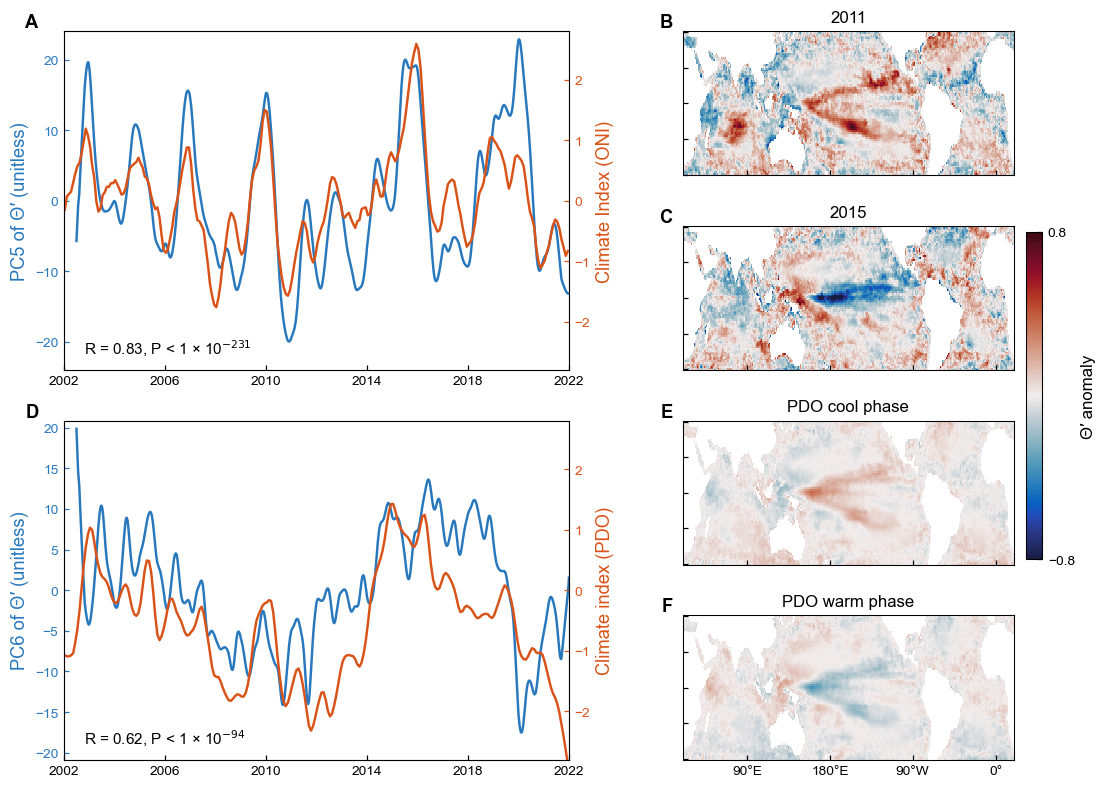

In [11]:
def yr_mean(years):
    return np.nanmean(np.stack([YEFF[YEARS.index(y)] for y in years if y in YEARS]), 0)


def lowess_t(t, y, span):
    o = np.argsort(t); out = np.empty_like(y); out[o] = lowess_matlab(y[o], span); return out


cool = list(range(2007, 2015)) + [2020, 2021]; warm = list(range(2002, 2007)) + list(range(2015, 2020))
sel = (ONI_T >= 2002) & (ONI_T <= 2022); selp = (PDO_T >= 2002) & (PDO_T <= 2022)
fig = plt.figure(figsize=(12, 8.6))
gs = fig.add_gridspec(4, 2, width_ratios=[1.25, 1], hspace=0.35, wspace=0.25)
for row, (k, tt, idx_t, idx_v, lab, Rk, letter) in enumerate([
        (4, TDEC, ONI_T[sel], ONI[sel], "Climate Index (ONI)", R5, "A"),
        (5, TDEC, PDO_T[selp], lowess_t(PDO_T[selp], PDO[selp], 10), "Climate index (PDO)", R6, "D")]):
    ax = fig.add_subplot(gs[2 * row:2 * row + 2, 0])
    ax.plot(TDEC, YY[:, k], color="#2878bd", lw=1.6); ax.set_ylabel(f"PC{k + 1} of Θ′ (unitless)", color="#2878bd", fontsize=12)
    ax.tick_params(axis="y", colors="#2878bd"); ax.set_xlim(2002, 2022); ax.set_xticks(range(2002, 2023, 4))
    lim = np.abs(YY[:, k]).max() * 1.05; ax.set_ylim(-lim, lim)
    ax2 = ax.twinx(); ax2.plot(idx_t, idx_v, color="#d95319", lw=1.6); ax2.set_ylim(-2.8, 2.8)
    ax2.set_ylabel(lab, color="#d95319", fontsize=12); ax2.tick_params(axis="y", colors="#d95319", direction="in")
    pexp = int(np.floor(np.log10(max(Rk[1], 1e-300))))
    ax.text(0.04, 0.05, f"R = {Rk[0]:.2f}, P < 1 × 10$^{{{pexp + 1}}}$", transform=ax.transAxes, fontsize=10)
    plabel(ax, letter, -0.05, 1.0)
maps = [(YEFF[YEARS.index(2011)], "2011", "B"), (YEFF[YEARS.index(2015)], "2015", "C"),
        (yr_mean(cool), "PDO cool phase", "E"), (yr_mean(warm), "PDO warm phase", "F")]
for i, (Z, ttl, letter) in enumerate(maps):
    ax = fig.add_subplot(gs[i, 1])
    im = pmap(ax, Z, BAL, -0.8, 0.8, xticks="four" if i == 3 else "none", yticks="none")
    ax.set_title(ttl, loc="center", fontsize=11); plabel(ax, letter, -0.03, 1.0)
cb = fig.colorbar(im, ax=fig.axes[-4:], shrink=0.45, pad=0.03); cb.set_ticks([-0.8, 0.8]); cb.set_label("Θ′ anomaly", fontsize=11)
save(fig, "Fig3")

### Fig. 4 — Contemporary trends

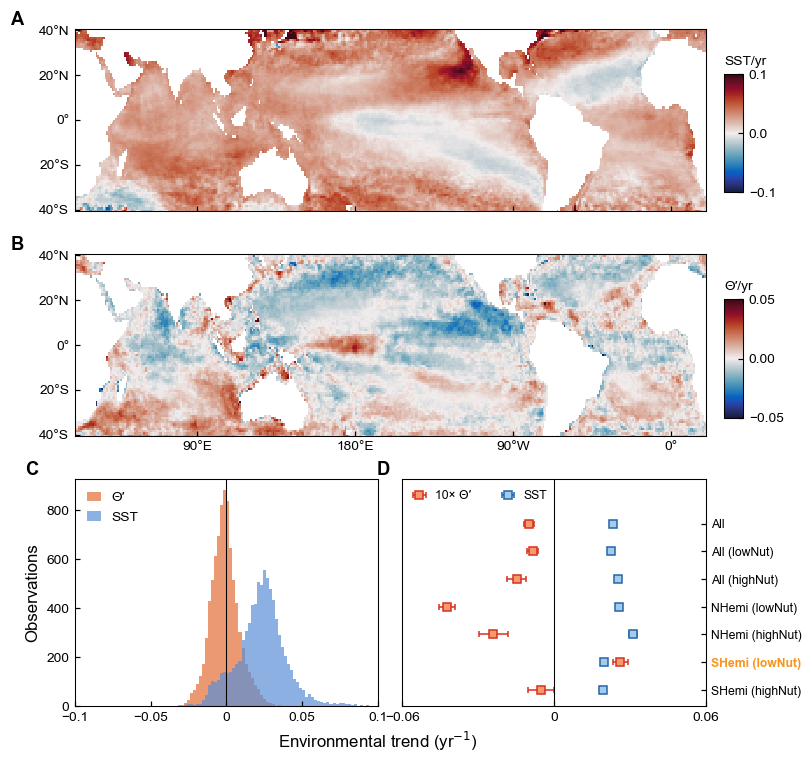

In [12]:
fig = plt.figure(figsize=(7.4, 8.0))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.25], hspace=0.22, wspace=0.08)
ax = fig.add_subplot(gs[0, :]); im = pmap(ax, TR_SST, BAL, -0.1, 0.1, xticks="none"); plabel(ax, "A", -0.08, 1.0)
cb = fig.colorbar(im, cax=ax.inset_axes([1.03, 0.1, 0.03, 0.65])); cb.set_ticks([-0.1, 0, 0.1]); cb.ax.set_title("SST/yr", fontsize=9)
ax = fig.add_subplot(gs[1, :]); im = pmap(ax, TR_TH, BAL, -0.05, 0.05, xticks="four"); plabel(ax, "B", -0.08, 1.0)
cb = fig.colorbar(im, cax=ax.inset_axes([1.03, 0.1, 0.03, 0.65])); cb.set_ticks([-0.05, 0, 0.05]); cb.ax.set_title("Θ′/yr", fontsize=9)
ax = fig.add_subplot(gs[2, 0]); bins = np.arange(-0.1, 0.1001, 0.002)
hm = okt & valid_reg                                  # grid cells with a nutricline value (as trend_byRegion_wSST.m)
ax.hist(TR_TH[hm], bins=bins, color="#e8875a", alpha=0.85, label="Θ′")
ax.hist(TR_SST[hm], bins=bins, color="#5b8fd6", alpha=0.7, label="SST")
ax.axvline(0, color="k", lw=0.7); ax.set_xlim(-0.1, 0.1); ax.set_xticks([-0.1, -0.05, 0, 0.05, 0.1]); ax.set_xticklabels(["−0.1", "−0.05", "0", "0.05", "0.1"])
ax.set_ylabel("Observations", fontsize=11); ax.legend(frameon=False, loc="upper left", handlelength=1); plabel(ax, "C", -0.12, 1.0)
ax.set_xlabel("Environmental trend (yr$^{-1}$)", fontsize=11, x=1.0)
ax = fig.add_subplot(gs[2, 1]); yy = np.arange(len(REG))[::-1]
ax.errorbar(REG["theta_x10"], yy, xerr=[REG["theta_x10"] - REG["theta_lo"], REG["theta_hi"] - REG["theta_x10"]], fmt="s", ms=5,
            mfc="#f59a6b", mec="#d7301f", ecolor="#d7301f", capsize=2, lw=1, label="10× Θ′")
ax.errorbar(REG["sst"], yy, xerr=[REG["sst"] - REG["sst_lo"], REG["sst_hi"] - REG["sst"]], fmt="s", ms=5,
            mfc="#a6cbe8", mec="#2166ac", ecolor="#2166ac", capsize=2, lw=1, label="SST")
ax.axvline(0, color="k", lw=0.7); ax.set_xlim(-0.06, 0.06); ax.set_xticks([-0.06, 0, 0.06]); ax.set_xticklabels(["−0.06", "0", "0.06"])
ax.yaxis.tick_right(); ax.set_yticks(yy); ax.set_yticklabels(REG.index, fontsize=8); ax.set_ylim(-0.6, len(REG) - 0.4)
for lab in ax.get_yticklabels():
    if lab.get_text() == "SHemi (lowNut)":
        lab.set_color("#f7941d"); lab.set_fontweight("bold")
ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(-0.02, 1.0), handletextpad=0.3, fontsize=8)
ax.set_ylim(-0.6, len(REG) + 0.6); plabel(ax, "D", -0.04, 1.0)
save(fig, "Fig4")

### Supplementary figures

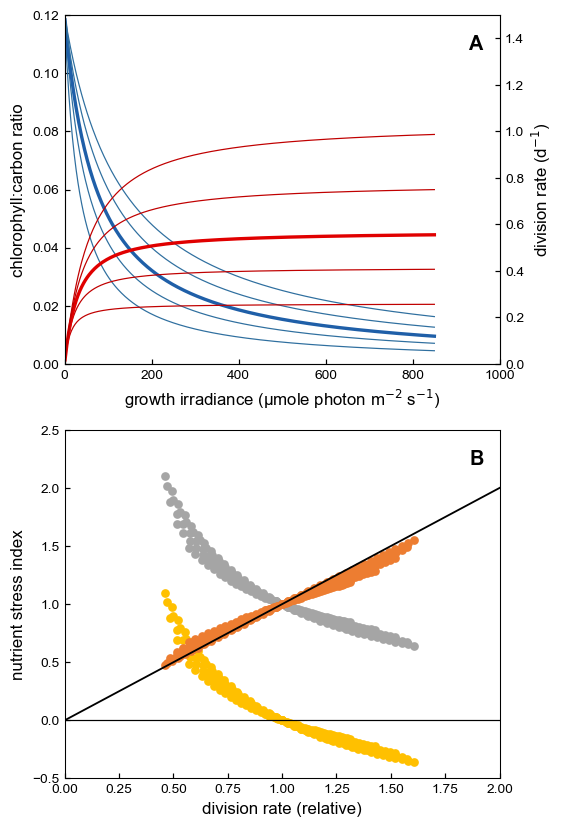

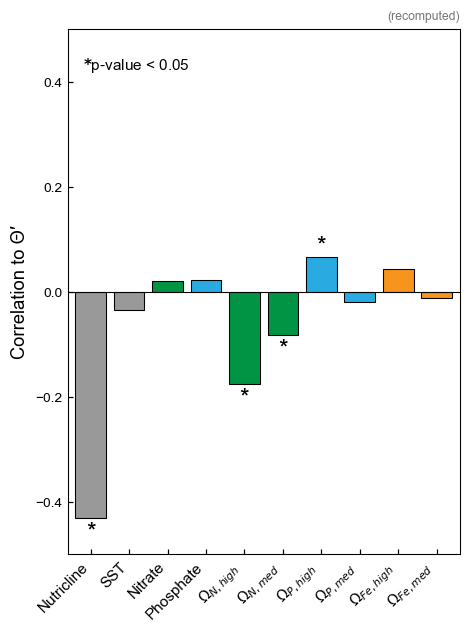

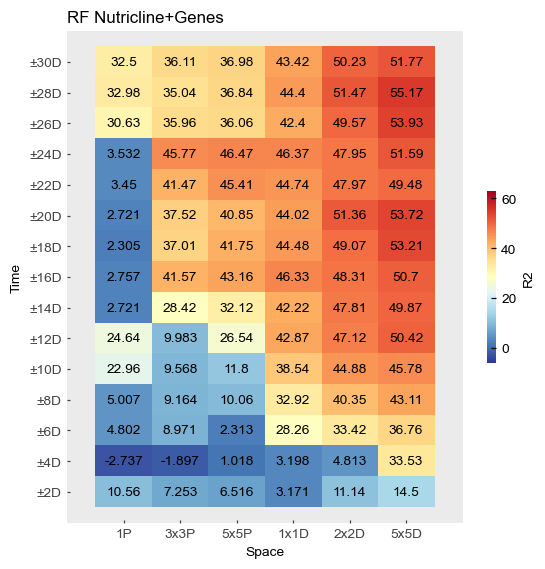

In [13]:
# S1: illustrative Geider-type model (assumed parameters), Θ = C:Chl
def geider(I, n, mu_max=1.2, chlc_max=0.12, alpha=0.15):
    Pm = mu_max * n; chlc = chlc_max / (1 + chlc_max * alpha * I / (2 * Pm))
    return chlc, Pm * (1 - np.exp(-alpha * chlc * I / Pm))


Iv = np.linspace(1, 850, 400); base = 0.55
fig, axs = plt.subplots(2, 1, figsize=(5.2, 7.6))
ax = axs[0]; ax2 = ax.twinx()
for n in [0.25, 0.4, 0.55, 0.75, 1.0]:
    c_, m_ = geider(Iv, n); heavy = n == base
    ax.plot(Iv, c_, color="#1f5fa8" if heavy else "#2f6f9f", lw=2.2 if heavy else 0.8)
    ax2.plot(Iv, m_, color="#e00000" if heavy else "#c00000", lw=2.2 if heavy else 0.8)
ax.set_xlim(0, 1000); ax.set_ylim(0, 0.12); ax2.set_ylim(0, 1.5)
ax.set_xlabel("growth irradiance (µmole photon m$^{-2}$ s$^{-1}$)", fontsize=11); ax.set_ylabel("chlorophyll:carbon ratio", fontsize=11)
ax2.set_ylabel("division rate (d$^{-1}$)", fontsize=11); ax.text(0.93, 0.9, "A", transform=ax.transAxes, fontsize=13, fontweight="bold")
rel, orng, gray, yel = [], [], [], []
for I0 in [50, 100, 200, 400, 800]:
    cb_, mb_ = geider(I0, base); co, mo = geider(I0, np.linspace(0.25, 0.9, 40))
    tp, to_ = 1 / cb_, 1 / co; rel += list(mo / mb_); orng += list(tp / to_); gray += list(to_ / tp); yel += list((to_ - tp) / tp)
ax = axs[1]; ax.plot([0, 2], [0, 2], color="k", lw=1.2); ax.axhline(0, color="k", lw=0.8)
ax.scatter(rel, gray, s=22, color="#a5a5a5"); ax.scatter(rel, yel, s=22, color="#ffc000"); ax.scatter(rel, orng, s=22, color="#ed7d31")
ax.set_xlim(0, 2); ax.set_ylim(-0.5, 2.5); ax.set_xlabel("division rate (relative)", fontsize=11); ax.set_ylabel("nutrient stress index", fontsize=11)
ax.text(0.93, 0.9, "B", transform=ax.transAxes, fontsize=13, fontweight="bold")
fig.tight_layout(); save(fig, "FigS1")

# S2
S2_LABELS = ["Nutricline", "SST", "Nitrate", "Phosphate", "Ω$_{N,high}$", "Ω$_{N,med}$", "Ω$_{P,high}$", "Ω$_{P,med}$", "Ω$_{Fe,high}$", "Ω$_{Fe,med}$"]
S2_PUBLISHED = [-0.43, -0.035, 0.02, 0.02, -0.175, -0.08, 0.065, -0.02, 0.045, -0.01]
if HAVE_INSITU:
    s2v = [s.statistic for s in S2_STATS]; s2p = [s.pvalue for s in S2_STATS]; s2t = "(recomputed)"
else:
    s2v, s2p, s2t = S2_PUBLISHED, [0.01, 1, 1, 1, 0.01, 0.01, 0.01, 1, 1, 1], "(published values)"
fig, ax = plt.subplots(figsize=(4.6, 6.2))
cols = ["#999999", "#999999", "#009444", "#29abe2", "#009444", "#009444", "#29abe2", "#29abe2", "#f7941d", "#f7941d"]
ax.bar(range(10), s2v, color=cols, edgecolor="k", lw=0.7, width=0.8)
for i, (v, p) in enumerate(zip(s2v, s2p)):
    if p < 0.05:
        ax.text(i, v + (0.008 if v > 0 else -0.04), "*", ha="center", fontsize=16)
ax.axhline(0, color="k", lw=0.7); ax.set_ylim(-0.5, 0.5); ax.set_xlim(-0.6, 9.6); ax.set_ylabel("Correlation to Θ′", fontsize=12)
ax.set_xticks(range(10)); ax.set_xticklabels(S2_LABELS, rotation=45, ha="right", fontsize=10)
ax.text(0.04, 0.95, "$\\bf{*}$p-value < 0.05", transform=ax.transAxes, fontsize=10, va="top")
ax.set_title(s2t, fontsize=8, loc="right", color="#777"); save(fig, "FigS2")

# S4
S4_PUBLISHED = np.array([[2.1, 5.23, 4.88, 0.2, 11.95, 16.93], [4.96, -5.78, 0.46, 1.04, 6.74, 36.63], [30.7, 7.36, 1.18, 32.92, 37.28, 41.1],
    [36.76, 8.26, 9.63, 36.4, 43.41, 46.84], [42.07, 8.32, 12.16, 42.17, 48.86, 49.71], [47.9, 9.63, 29.29, 47.75, 52.52, 55.71],
    [47.01, 33.52, 36.11, 46.93, 54.19, 56.17], [53.11, 49.62, 49.92, 53.83, 56.05, 58.46], [52.6, 43.96, 49.38, 52.03, 56.06, 61.11],
    [51.72, 43.52, 48.02, 51.57, 59.94, 60.65], [52.37, 47.13, 51.79, 53.36, 57.07, 59.6], [57.14, 53.91, 56.29, 56.97, 57.95, 60.77],
    [50.28, 41.54, 43.54, 50.64, 56.2, 62.11], [51.75, 42.19, 43.47, 51.29, 58.26, 62.33], [50.58, 41.45, 43.86, 50.9, 57.08, 56.91]])
G4 = S4_GRID if HAVE_INSITU else S4_PUBLISHED
fig, ax = plt.subplots(figsize=(5.8, 5.8)); fig.patch.set_facecolor("white"); ax.set_facecolor("#ebebeb")
im = ax.imshow(G4[::-1], cmap="RdYlBu_r", vmin=-6, vmax=63, aspect="auto", extent=(0.5, 6.5, 0.5, 15.5), origin="upper")
for i in range(15):
    for j in range(6):
        ax.text(j + 1, i + 1, f"{G4[i, j]:.4g}", ha="center", va="center", fontsize=9)
ax.set_xlim(0, 7); ax.set_ylim(0, 16); ax.set_xticks(range(1, 7)); ax.set_xticklabels(["1P", "3x3P", "5x5P", "1x1D", "2x2D", "5x5D"])
ax.set_yticks(range(1, 16)); ax.set_yticklabels([f"±{d}D" for d in range(2, 31, 2)]); ax.set_xlabel("Space"); ax.set_ylabel("Time")
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=2, colors="#444"); cb = fig.colorbar(im, ax=ax, shrink=0.35); cb.set_label("R2"); cb.outline.set_visible(False)
ax.set_title("RF Nutricline+Genes" + ("" if HAVE_INSITU else " (published)"), fontsize=11); save(fig, "FigS4")

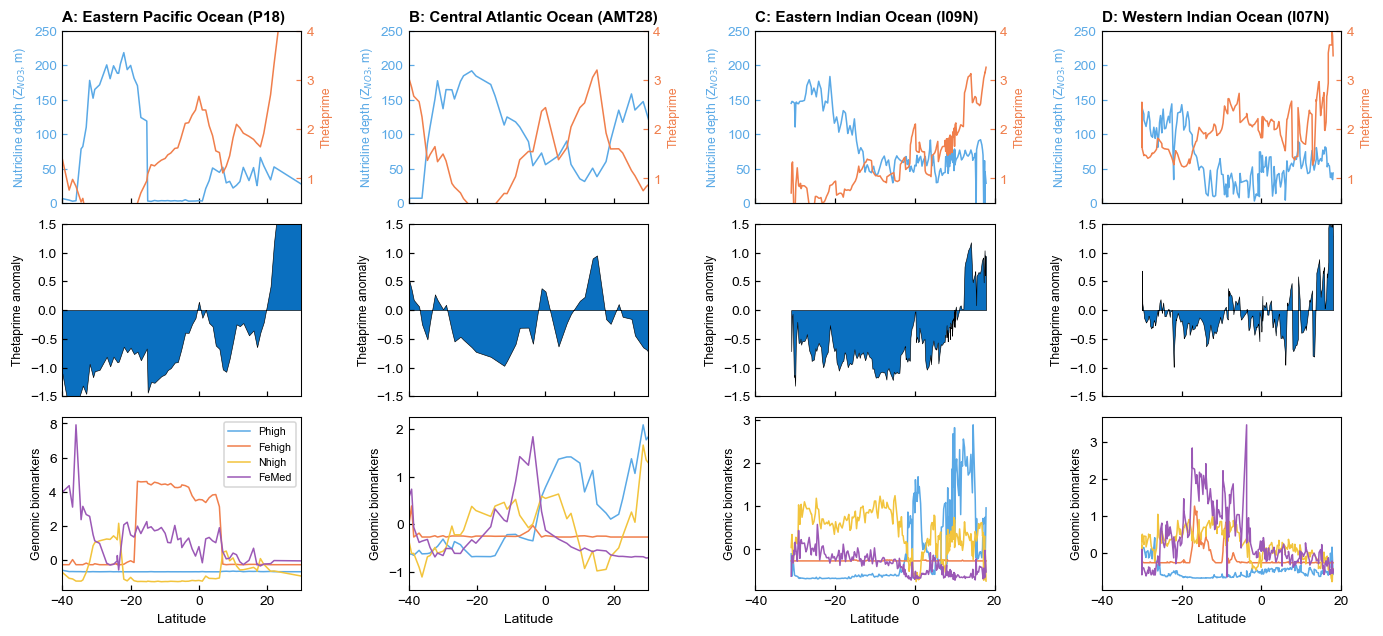

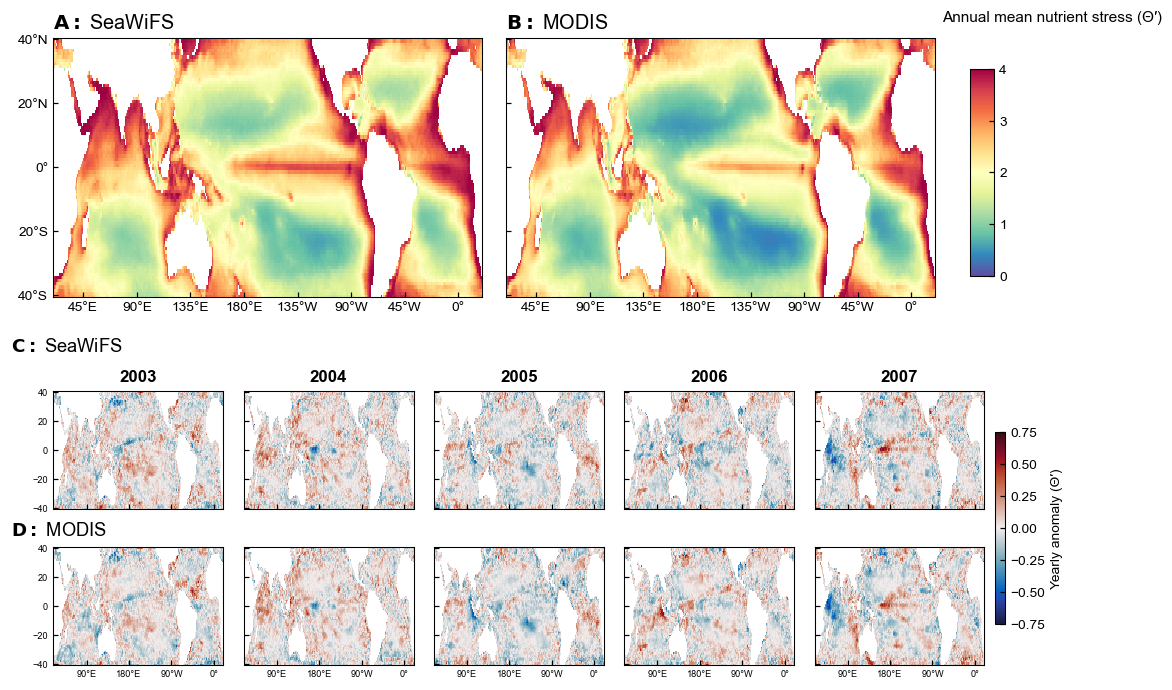

In [14]:
# S5: cruise sections. Θ′ anomaly = Θ′ − linear fit of Θ′ on nitracline across grid boxes (Fig. 1A)
if HAVE_INSITU:
    if ZNO3 is not None:
        okf = np.isfinite(GEO) & np.isfinite(ZNO3); BFIT = np.polyfit(ZNO3[okf], GEO[okf], 1)
    else:
        BFIT = np.polyfit(INS.loc[M20, COLS["nutricline"]], TH20[M20], 1)
    INS["theta20"] = TH20; INS["theta_anom"] = TH20 - np.polyval(BFIT, INS[COLS["nutricline"]])
    secs = [("A: Eastern Pacific Ocean (P18)", "P18"), ("B: Central Atlantic Ocean (AMT28)", "AMT28"),
            ("C: Eastern Indian Ocean (I09N)", "IO9N"), ("D: Western Indian Ocean (I07N)", "I07N")]
    fig, axs = plt.subplots(3, 4, figsize=(15, 6.6), gridspec_kw={"hspace": 0.12, "wspace": 0.45})
    for j, (ttl, cr) in enumerate(secs):
        d = INS[INS[COLS["cruise"]] == cr].sort_values(COLS["lat"]); x = d[COLS["lat"]].values
        ax = axs[0, j]; ax.plot(x, d[COLS["nutricline"]], color="#5aa9e6", lw=1); ax.set_ylim(0, 250)
        ax.set_ylabel("Nutricline depth (Z$_{NO3}$, m)", color="#5aa9e6", fontsize=8); ax.tick_params(axis="y", colors="#5aa9e6")
        a2 = ax.twinx(); a2.plot(x, d["theta20"], color="#f07f4c", lw=1); a2.set_ylim(0.5, 4)
        a2.set_ylabel("Thetaprime", color="#f07f4c", fontsize=8); a2.tick_params(axis="y", colors="#f07f4c", direction="in")
        ax.set_title(ttl, fontsize=10, fontweight="bold")
        ax = axs[1, j]; an = d["theta_anom"].values; okx = np.isfinite(an)
        ax.fill_between(x[okx], 0, an[okx], color="#0a6fbf", lw=0.4, edgecolor="k"); ax.set_ylim(-1.5, 1.5)
        ax.set_ylabel("Thetaprime anomaly", fontsize=8)
        ax = axs[2, j]
        for k, c_, lab in [("PH", "#5aa9e6", "Phigh"), ("FeH", "#f07f4c", "Fehigh"), ("NH", "#f2c43d", "Nhigh"), ("FeM", "#9b59b6", "FeMed")]:
            ax.plot(x, d[COLS[k]], color=c_, lw=1, label=lab)
        ax.set_ylabel("Genomic biomarkers", fontsize=8); ax.set_xlabel("Latitude")
        if j == 0:
            ax.legend(fontsize=7, loc="upper right")
        lo = -40; hi = 30 if j < 2 else 20
        for r_ in range(3):
            axs[r_, j].set_xlim(lo, hi)
            if r_ < 2:
                axs[r_, j].set_xticklabels([])
    save(fig, "FigS5")

# S6
if have("seawifs"):
    fig = plt.figure(figsize=(13, 7.4))
    gs = fig.add_gridspec(4, 5, height_ratios=[2.2, 0.15, 1, 1], hspace=0.3, wspace=0.12)
    for i, nm in enumerate(["SeaWiFS", "MODIS"]):
        ax = fig.add_subplot(gs[0, 0:2] if i == 0 else gs[0, 2:4])
        im = pmap(ax, S6_MEAN[nm].reshape(NY, NX), SPEC_R, 0, 4, yticks="deg" if i == 0 else "none")
        ax.set_title(f"$\\bf{{{'AB'[i]}:}}$ {nm}", fontsize=13)
    cb = fig.colorbar(im, cax=fig.add_subplot(gs[0, 4]).inset_axes([0.05, 0.08, 0.12, 0.8])); fig.axes[2].axis("off")
    fig.text(0.9, 0.9, "Annual mean nutrient stress (Θ′)", fontsize=10, ha="right")
    for r, nm in enumerate(["SeaWiFS", "MODIS"]):
        for k, y in enumerate(range(2003, 2008)):
            ax = fig.add_subplot(gs[2 + r, k])
            im = pmap(ax, S6_DEV[nm][k].reshape(NY, NX), BAL, -0.75, 0.75, xticks="four" if r == 1 else "none", yticks="num" if k == 0 else "none")
            ax.tick_params(labelsize=6)
            if r == 0:
                ax.set_title(str(y), loc="center", fontweight="bold")
            if k == 0:
                ax.text(-0.25, 1.3 if r == 0 else 1.06, f"$\\bf{{{'CD'[r]}:}}$ {nm}", transform=ax.transAxes, fontsize=12, va="bottom")
    cb = fig.colorbar(im, ax=fig.axes[-10:], shrink=0.7, pad=0.01); cb.set_label("Yearly anomaly (Θ′)")
    save(fig, "FigS6")

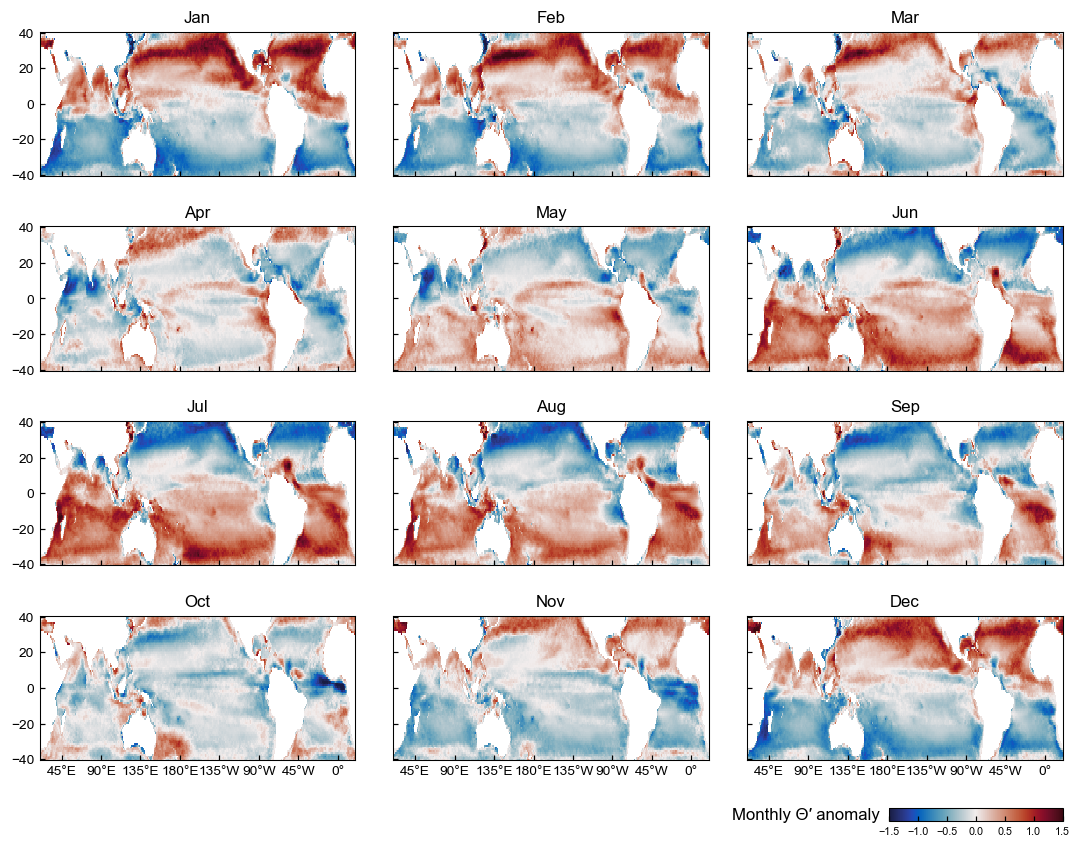

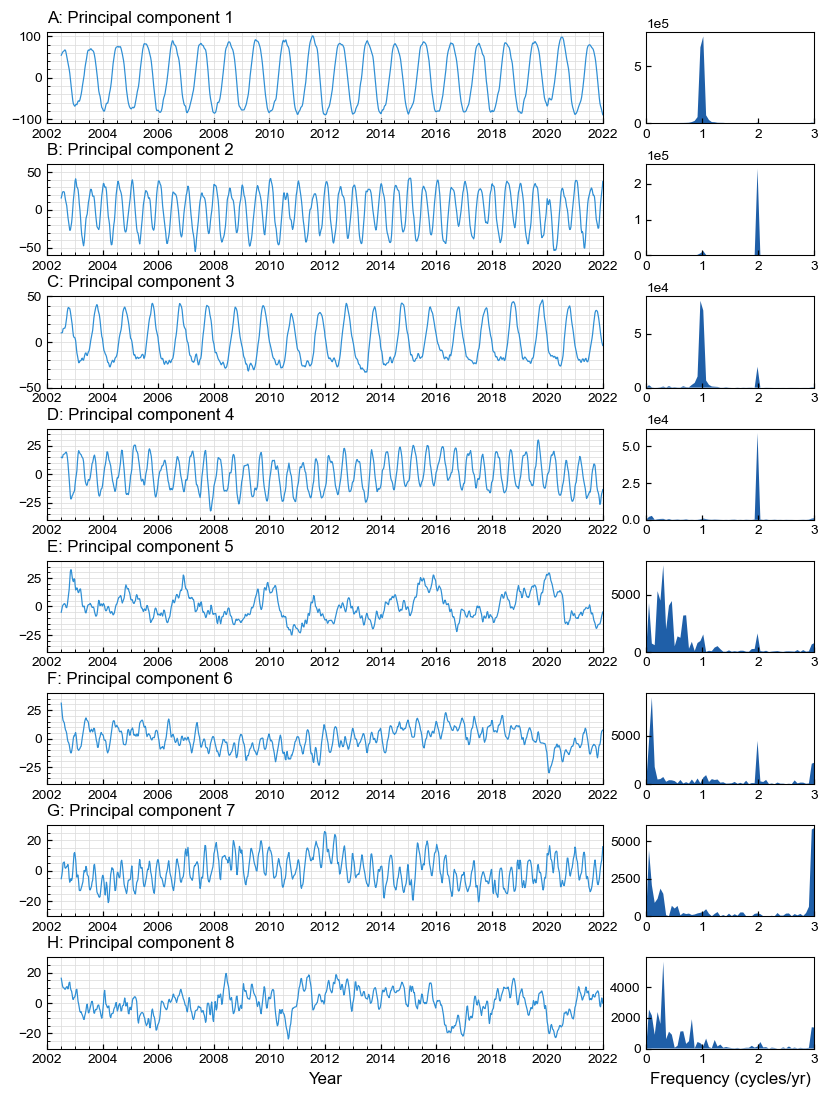

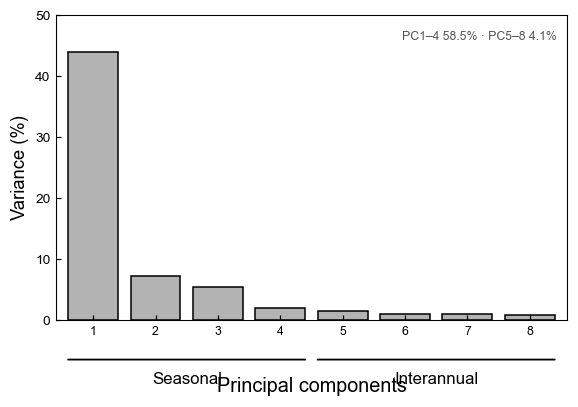

In [15]:
# S7 monthly anomalies
names_m = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()
fig, axs = plt.subplots(4, 3, figsize=(12, 8.6), gridspec_kw={"hspace": 0.35, "wspace": 0.12})
for i, ax in enumerate(axs.ravel()):
    im = pmap(ax, MEFF[i], BAL, -1.5, 1.5, xticks="all" if i >= 9 else "ticks", yticks="num" if i % 3 == 0 else "none")
    ax.set_title(names_m[i], loc="center", fontsize=11)
cb = fig.colorbar(im, cax=axs[3, 2].inset_axes([0.45, -0.42, 0.55, 0.09]), orientation="horizontal")
cb.set_ticks([-1.5, -1, -0.5, 0, 0.5, 1, 1.5]); cb.ax.tick_params(labelsize=7)
axs[3, 2].text(0.42, -0.38, "Monthly Θ′ anomaly", transform=axs[3, 2].transAxes, ha="right", va="center", fontsize=11)
save(fig, "FigS7")

# S8 PCs and periodograms
freq = np.fft.rfftfreq(T, d=8 / 365.25)
fig, axs = plt.subplots(NM, 2, figsize=(9, 12), gridspec_kw={"width_ratios": [3.3, 1], "hspace": 0.45, "wspace": 0.12})
for k in range(NM):
    ax = axs[k, 0]; ax.plot(TDEC, PCS[:, k], color="#2f8fd5", lw=0.8)
    lim = np.ceil(np.abs(PCS[:, k]).max() / 10) * 10; ax.set_ylim(-lim, lim); ax.set_xlim(2002, 2022)
    ax.set_xticks(range(2002, 2023, 2)); ax.grid(True, which="both", color="#dddddd", lw=0.5); ax.minorticks_on()
    ax.set_title(f"{'ABCDEFGH'[k]}: Principal component {k + 1}", fontsize=11)
    p = np.abs(np.fft.rfft(PCS[:, k] - PCS[:, k].mean())) ** 2 / T
    axs[k, 1].fill_between(freq, p, color="#1f5fa8", lw=0); axs[k, 1].set_xlim(0, 3); axs[k, 1].set_ylim(0, p[freq <= 3].max() * 1.05)
    axs[k, 1].ticklabel_format(axis="y", style="sci", scilimits=(0, 4))
axs[-1, 0].set_xlabel("Year", fontsize=11); axs[-1, 1].set_xlabel("Frequency (cycles/yr)", fontsize=11)
save(fig, "FigS8")

# S9 variance by mode
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(range(1, 9), VAR[:8], color="#b3b3b3", edgecolor="k", width=0.8); ax.set_ylim(0, 50); ax.set_xlim(0.4, 8.6)
ax.set_xticks(range(1, 9)); ax.tick_params(axis="x", labelsize=8); ax.set_ylabel("Variance (%)", fontsize=12)
for x0, x1, t_ in [(0.55, 4.45, "Seasonal"), (4.55, 8.45, "Interannual")]:
    ax.annotate("", xy=(x0, -6.5), xytext=(x1, -6.5), xycoords="data", arrowprops=dict(arrowstyle="-", lw=1.2), annotation_clip=False)
    ax.text((x0 + x1) / 2, -10.5, t_, ha="center", fontsize=11, clip_on=False)
ax.set_xlabel("Principal components", fontsize=13, labelpad=26)
ax.text(0.98, 0.95, f"PC1–4 {VAR[:4].sum():.1f}% · PC5–8 {VAR[4:8].sum():.1f}%", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#555")
save(fig, "FigS9")

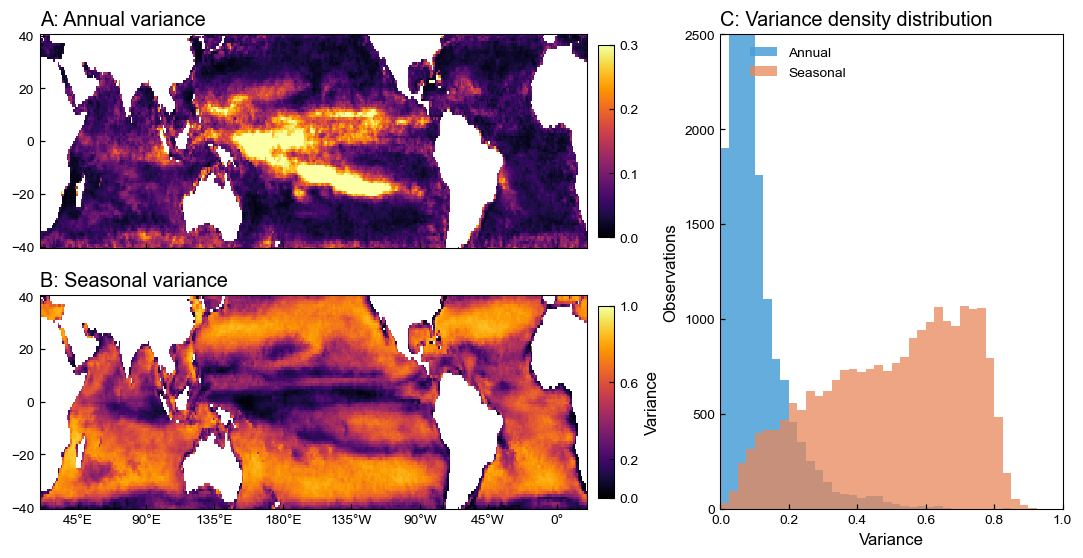

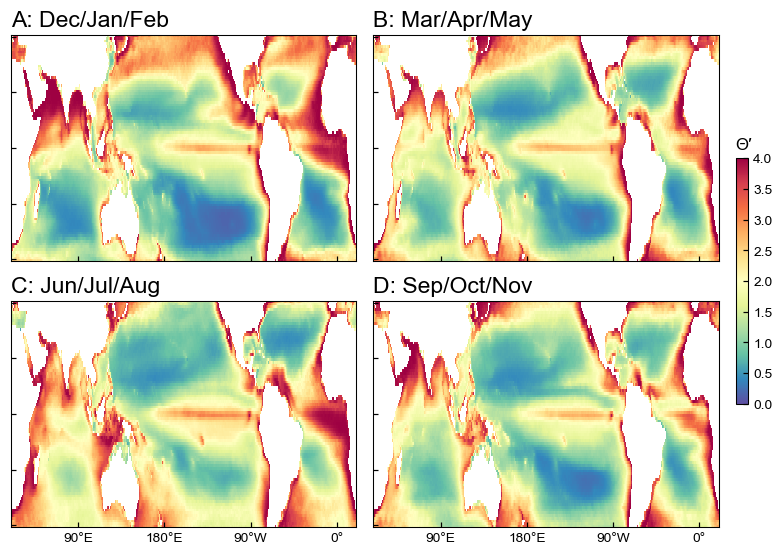

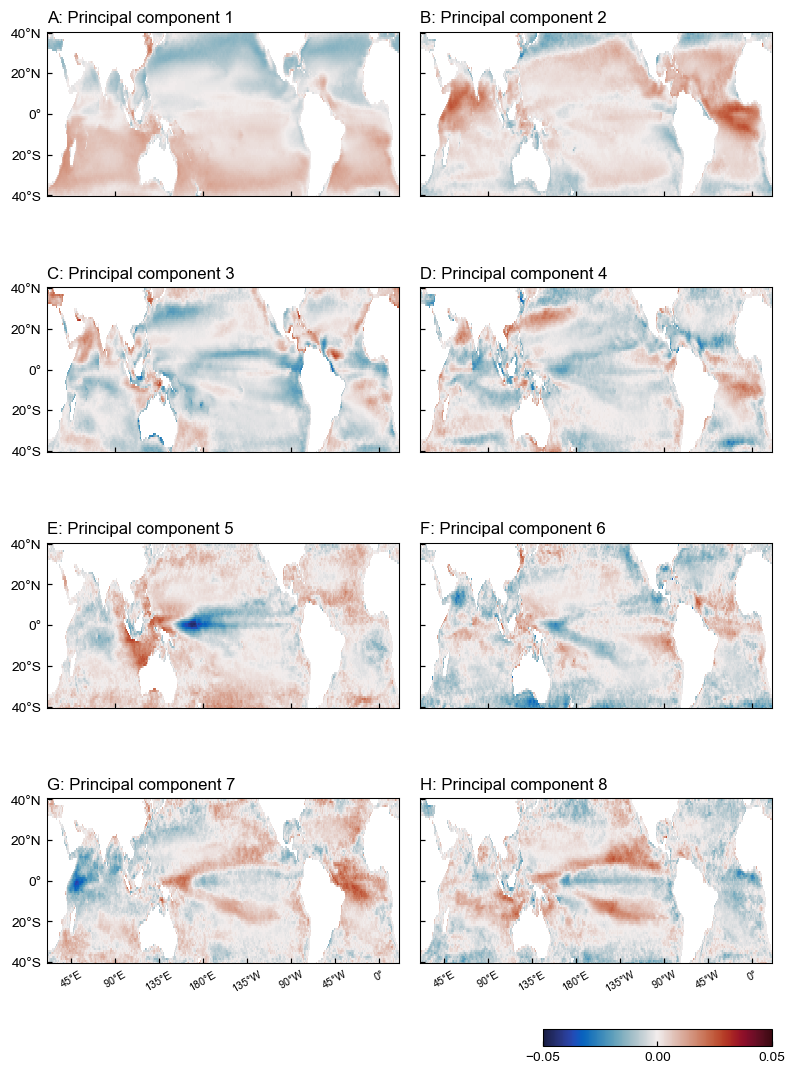

In [16]:
# S10 variance partition (ANOVA)
fig = plt.figure(figsize=(12, 5.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.6, 1], hspace=0.22, wspace=0.3)
ax = fig.add_subplot(gs[0, 0]); im = pmap(ax, FRAC_Y, "inferno", 0, 0.3, xticks="none", yticks="num"); ax.set_title("A: Annual variance", fontsize=13)
cb = fig.colorbar(im, cax=ax.inset_axes([1.02, 0.05, 0.03, 0.9])); cb.set_ticks([0, 0.1, 0.2, 0.3])
ax = fig.add_subplot(gs[1, 0]); im = pmap(ax, FRAC_M, "inferno", 0, 1, xticks="all", yticks="num"); ax.set_title("B: Seasonal variance", fontsize=13)
cb = fig.colorbar(im, cax=ax.inset_axes([1.02, 0.05, 0.03, 0.9])); cb.set_ticks([0, 0.2, 0.6, 1]); cb.set_label("Variance", fontsize=11)
ax = fig.add_subplot(gs[:, 1]); bins = np.arange(0, 1.0001, 0.025)
ax.hist(FRAC_Y[np.isfinite(FRAC_Y)], bins=bins, color="#4a9fd8", alpha=0.85, label="Annual")
ax.hist(FRAC_M[np.isfinite(FRAC_M)], bins=bins, color="#e8875a", alpha=0.75, label="Seasonal")
ax.set_xlim(0, 1); ax.set_ylim(0, 2500); ax.set_xlabel("Variance", fontsize=11); ax.set_ylabel("Observations", fontsize=11)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.05, 1)); ax.set_title("C: Variance density distribution", fontsize=13)
save(fig, "FigS10")

# S11 seasonal means
seasons = {"A: Dec/Jan/Feb": [12, 1, 2], "B: Mar/Apr/May": [3, 4, 5], "C: Jun/Jul/Aug": [6, 7, 8], "D: Sep/Oct/Nov": [9, 10, 11]}
LTH = np.log(np.clip(TH, 1e-3, None))
fig, axs = plt.subplots(2, 2, figsize=(10, 5.8), gridspec_kw={"hspace": 0.18, "wspace": 0.05})
for i, (ax, (nm, ms)) in enumerate(zip(axs.ravel(), seasons.items())):
    Z = np.exp(np.nanmean(LTH[np.isin(MON, ms)], 0)).reshape(NY, NX); Z[~KEEP.reshape(NY, NX)] = np.nan
    im = pmap(ax, Z, SPEC_R, 0, 4, xticks="four" if i >= 2 else "none", yticks="none"); ax.set_title(nm, fontsize=15)
cb = fig.colorbar(im, ax=axs, shrink=0.5, pad=0.02); cb.ax.set_title("Θ′", fontsize=11)
save(fig, "FigS11")

# S12 EOF loadings
fig, axs = plt.subplots(4, 2, figsize=(8.5, 11), gridspec_kw={"hspace": 0.55, "wspace": 0.06})
for k, ax in enumerate(axs.ravel()):
    im = pmap(ax, to_map(LOADS[k]), BAL, -0.05, 0.05, xticks="all" if k >= 6 else "none", yticks="deg" if k % 2 == 0 else "none")
    ax.set_title(f"{'ABCDEFGH'[k]}: Principal component {k + 1}", fontsize=11); ax.tick_params(axis="x", labelrotation=30, labelsize=7)
cb = fig.colorbar(im, cax=axs[3, 1].inset_axes([0.35, -0.5, 0.65, 0.1]), orientation="horizontal"); cb.set_ticks([-0.05, 0, 0.05])
save(fig, "FigS12")

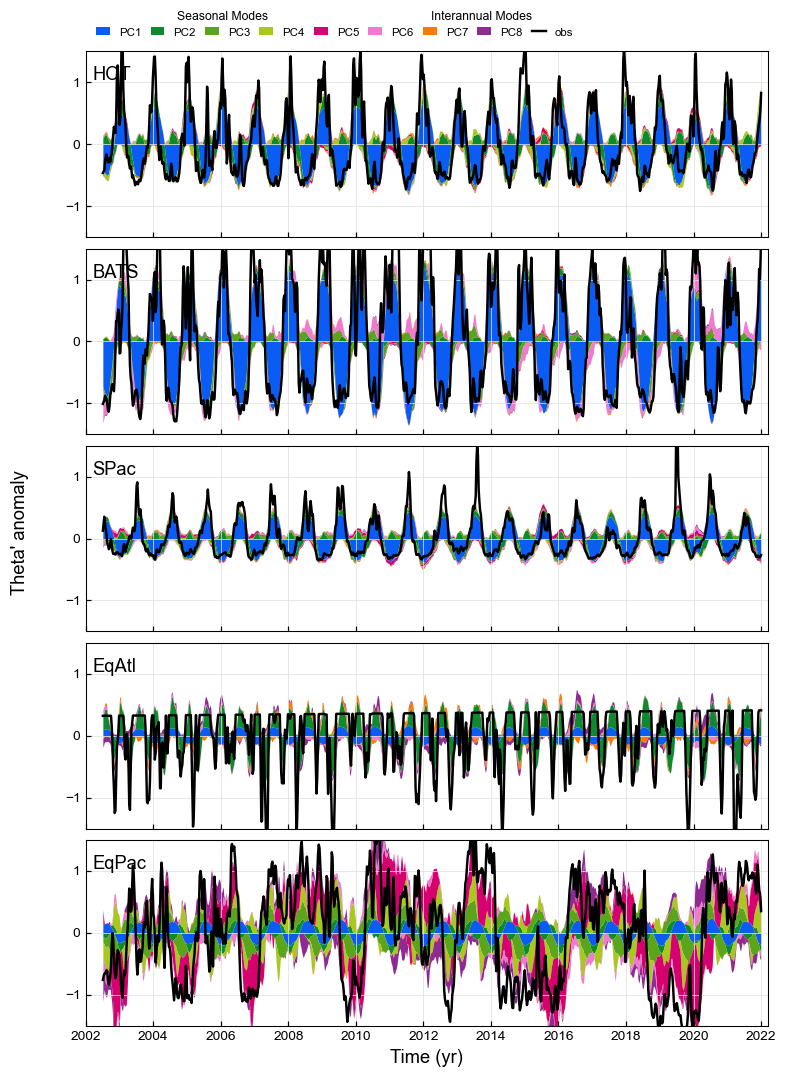

,sd_seasonal,var_PC1_4,var_PC5_8
HOT,0.50,0.78,0.01
BATS,0.84,0.80,0.02
SPac,0.28,0.75,0.01
EqAtl,0.35,0.50,0.04
EqPac,0.38,0.22,0.46


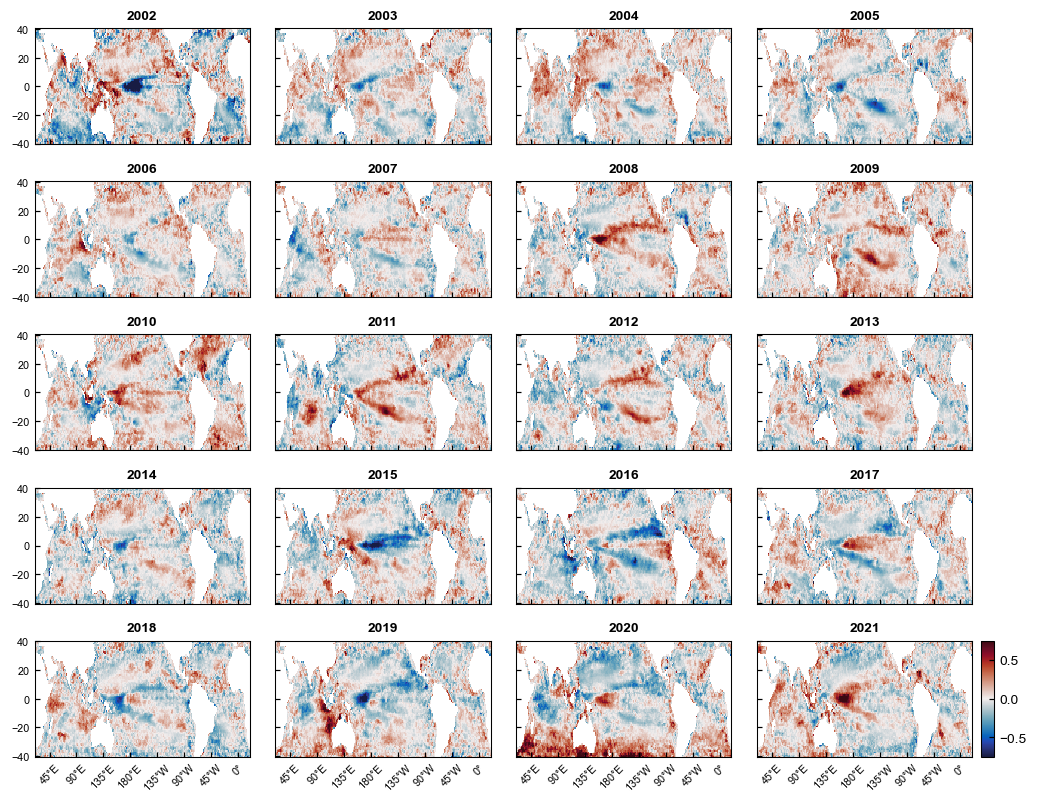

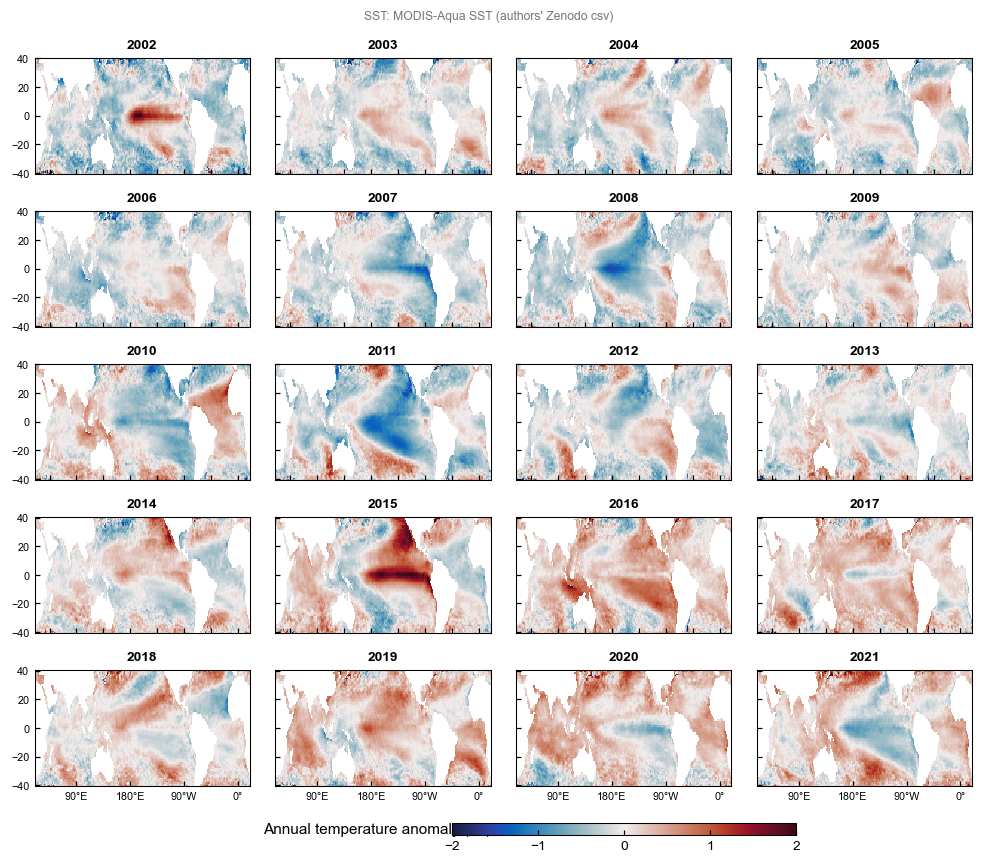

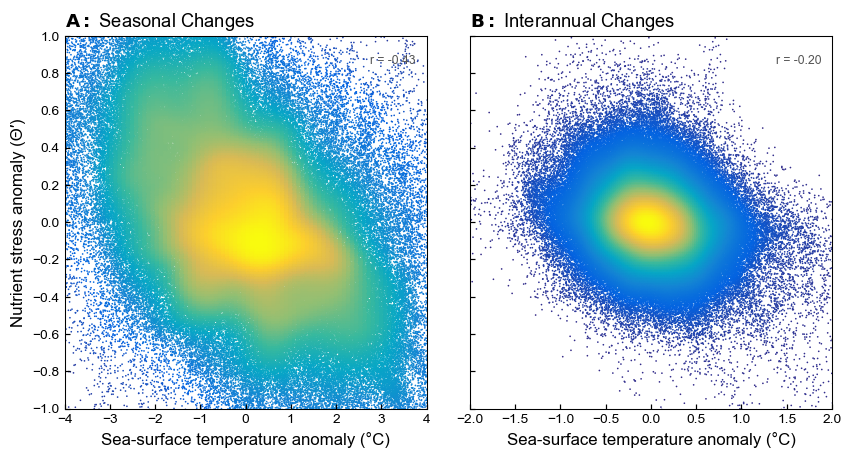

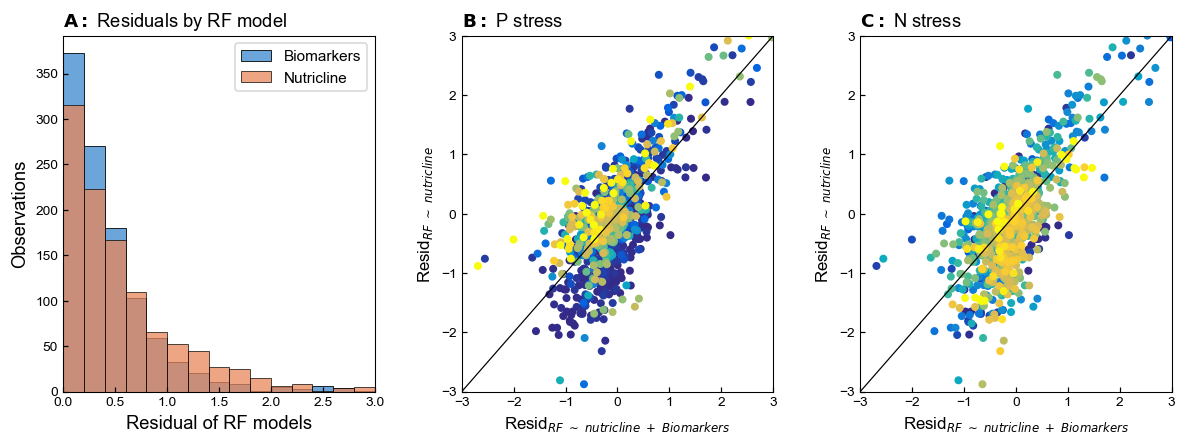

In [17]:
# S13 sites: observed (detrended) and stacked contributions of PC1-8
sites = {"HOT": (22.5, -158), "BATS": (31.5, -64), "SPac": (-25, -130), "EqAtl": (0, -10), "EqPac": (1, 170)}
PC_COLORS = ["#0a5cf5", "#0b8a2e", "#5aa51c", "#a8c81e", "#d6006f", "#f07ad1", "#ff7a00", "#8e2a91"]
pix = np.where(KEEP)[0]
fig, axs = plt.subplots(len(sites), 1, figsize=(8, 11.5), sharex=True, gridspec_kw={"hspace": 0.06})
RES["sites"] = {}
for ax, (nm, (la, lo)) in zip(axs, sites.items()):
    c = np.where(pix == np.argmin(np.abs(LAT - la)) * NX + np.argmin(np.abs(LON - lo)))[0][0]
    contrib = PCS * LOADS[:, c]; obs = X[:, c]
    pos_base, neg_base = np.zeros(T), np.zeros(T)
    for k in range(NM):
        v = contrib[:, k]; vp, vn = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.fill_between(TDEC, pos_base, pos_base + vp, color=PC_COLORS[k], lw=0, label=f"PC{k + 1}")
        ax.fill_between(TDEC, neg_base, neg_base + vn, color=PC_COLORS[k], lw=0)
        pos_base += vp; neg_base += vn
    ax.plot(TDEC, obs, color="k", lw=1.6, label="obs"); ax.set_ylim(-1.5, 1.5); ax.set_yticks([-1, 0, 1])
    ax.grid(True, color="#e0e0e0", lw=0.5); ax.text(0.01, 0.92, nm, transform=ax.transAxes, fontsize=12, va="top")
    rs = PCS[:, :4] @ LOADS[:4, c]; ri = PCS[:, 4:8] @ LOADS[4:8, c]
    RES["sites"][nm] = dict(sd_seasonal=float(rs.std()), var_PC1_4=float(1 - np.var(obs - rs) / np.var(obs)), var_PC5_8=float(1 - np.var(obs - ri) / np.var(obs)))
axs[0].legend(ncol=9, fontsize=7.5, loc="lower left", bbox_to_anchor=(0, 1.02), frameon=False, handlelength=1.2, columnspacing=0.8)
axs[0].text(0.2, 1.17, "Seasonal Modes", transform=axs[0].transAxes, ha="center", fontsize=8)
axs[0].text(0.58, 1.17, "Interannual Modes", transform=axs[0].transAxes, ha="center", fontsize=8)
axs[-1].set_xlim(2002, 2022.2); axs[-1].set_xticks(range(2002, 2023, 2)); axs[-1].set_xlabel("Time (yr)", fontsize=12)
fig.text(0.04, 0.5, "Theta' anomaly", rotation=90, va="center", fontsize=12)
save(fig, "FigS13")
display(pd.DataFrame(RES["sites"]).T.round(2))

# S14 / S15 yearly anomalies (ANOVA year effects) for Θ′ and SST
for Z_, cmap_, lim_, lab_, nm_ in [(YEFF, BAL, 0.75, "", "FigS14"), (YEFF_S, BAL, 2, "Annual temperature anomaly (°C)", "FigS15")]:
    fig, axs = plt.subplots(5, 4, figsize=(11, 8.6), gridspec_kw={"hspace": 0.32, "wspace": 0.12})
    for k, ax in enumerate(axs.ravel()):
        im = pmap(ax, Z_[k], cmap_, -lim_, lim_, xticks=("all" if nm_ == "FigS14" else "four") if k >= 16 else "ticks",
                  yticks="num" if k % 4 == 0 else "none")
        ax.set_title(str(YEARS[k]), loc="center", fontsize=9, fontweight="bold"); ax.tick_params(labelsize=7)
        if k >= 16 and nm_ == "FigS14":
            ax.tick_params(axis="x", labelrotation=45)
    if nm_ == "FigS14":
        cb = fig.colorbar(im, cax=axs[4, 3].inset_axes([1.04, 0, 0.06, 1])); cb.set_ticks([-0.5, 0, 0.5])
    else:
        cb = fig.colorbar(im, cax=axs[4, 2].inset_axes([-0.3, -0.42, 1.6, 0.1]), orientation="horizontal")
        cb.set_ticks([-2, -1, 0, 1, 2]); axs[4, 1].text(1.0, -0.37, lab_, transform=axs[4, 1].transAxes, ha="right", va="center", fontsize=10)
        fig.text(0.5, 0.92, f"SST: {SST_SRC}", ha="center", fontsize=8, color="#777")
    save(fig, nm_)

# S16 density scatter
fig, axs = plt.subplots(1, 2, figsize=(9, 4.4), gridspec_kw={"wspace": 0.12})
for ax, (xs, ys, ttl, xl) in zip(axs, [(MEFF_S, MEFF, "A:", "Seasonal Changes"), (YEFF_S, YEFF, "B:", "Interannual Changes")]):
    xv, yv = xs.ravel(), ys.ravel(); ok = np.isfinite(xv) & np.isfinite(yv); xv, yv = xv[ok], yv[ok]
    from scipy.ndimage import gaussian_filter
    H, xe, ye = np.histogram2d(xv, yv, bins=300); H = gaussian_filter(H, 4)            # kernel-density-like
    ix = np.clip(np.searchsorted(xe, xv) - 1, 0, 299); iy = np.clip(np.searchsorted(ye, yv) - 1, 0, 299)
    dens = H[ix, iy]; o = np.argsort(dens)
    ax.scatter(xv[o], yv[o], c=np.sqrt(dens[o]), s=1.2, cmap=PARULA, lw=0, rasterized=True)
    ax.set_yticks(np.round(np.arange(-1, 1.01, 0.2), 1))
    lim = 4 if ttl == "A:" else 2; ax.set_xlim(-lim, lim); ax.set_ylim(-1, 1)
    ax.set_title(f"$\\bf{{{ttl}}}$ {xl}", fontsize=12); ax.set_xlabel("Sea-surface temperature anomaly (°C)", fontsize=11)
    r_ = np.corrcoef(xv, yv)[0, 1]; ax.text(0.97, 0.95, f"r = {r_:.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#555")
axs[0].set_ylabel("Nutrient stress anomaly (Θ′)", fontsize=11); axs[1].set_yticklabels([])
save(fig, "FigS16")

# S17 RF residuals
if HAVE_INSITU:
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"wspace": 0.28})
    ax = axs[0]; bins = np.arange(0, 3.01, 0.2)
    ax.hist(np.abs(RES_F), bins=bins, color="#5b9bd5", edgecolor="k", lw=0.6, alpha=0.9, label="Biomarkers")
    ax.hist(np.abs(RES_N), bins=bins, color="#e8875a", edgecolor="k", lw=0.6, alpha=0.75, label="Nutricline")
    ax.legend(frameon=True, fontsize=10); ax.set_xlim(0, 3); ax.set_xlabel("Residual of RF models", fontsize=12); ax.set_ylabel("Observations", fontsize=12)
    ax.set_title("$\\bf{A:}$ Residuals by RF model", fontsize=12)
    for ax, k, ttl in [(axs[1], "PH", "B: P stress"), (axs[2], "NH", "C: N stress")]:
        cval = INS.loc[M20, COLS[k]].values; o = np.argsort(cval)
        ax.scatter(RES_F[o], RES_N[o], c=cval[o], cmap=PARULA, s=18, vmin=np.percentile(cval, 2), vmax=np.percentile(cval, 98))
        ax.plot([-3, 3], [-3, 3], color="k", lw=0.8); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
        ax.set_xlabel("Resid$_{RF\\ \\sim\\ nutricline\\ +\\ Biomarkers}$", fontsize=11); ax.set_ylabel("Resid$_{RF\\ \\sim\\ nutricline}$", fontsize=11)
        ax.set_title(f"$\\bf{{{ttl.split(':')[0]}:}}$ {ttl.split(': ')[1]}", fontsize=12)
    save(fig, "FigS17")

## 6. Summary: paper vs this reproduction

In [18]:
def g(k, f="{:.2f}"):
    v = RES.get(k); return "—" if v is None else f.format(v)


rg = RES["regions"]
summary = pd.DataFrame([
    ("Pixels analysed", "22,468 (trend script)", g("n_pixels", "{:,}")),
    ("EOF PC1–4 / PC5–8 / PC1–8 (%)", "59.4 / 4.2 / 63.6", f"{g('eof_1_4', '{:.1f}')} / {g('eof_5_8', '{:.1f}')} / {g('eof_1_8', '{:.1f}')}"),
    ("PC5 vs ONI (R)", "0.81", g("r_PC5_ONI") + f"  [{ONI_SRC}]"),
    ("PC6 vs PDO (R)", "0.59", g("r_PC6_PDO") + f"  [{PDO_SRC}]"),
    ("Seasonal SST vs Θ′ (r)", "−0.51", g("S16_r_seasonal")),
    ("Year-to-year SST vs Θ′ (r)", "−0.23", g("S16_r_annual")),
    ("Median Θ′ trend (yr⁻¹)", "−1.3e−3", g("trend_theta_median", "{:.2e}")),
    ("Median SST trend (°C yr⁻¹)", "2.3e−2", g("trend_sst_median", "{:.2e}") + f"  [{SST_SRC.split(' (')[0]}]"),
    ("Area with SST warming", "89%", g("frac_area_sst_up", "{:.0%}")),
    ("SHemi (lowNut) Θ′ trend ×10", "≈ +0.03", f"{rg.loc['SHemi (lowNut)', 'theta_x10']:+.4f}  [{REGIME_SRC}]"),
    ("NHemi (lowNut) Θ′ trend ×10", "≈ −0.05", f"{rg.loc['NHemi (lowNut)', 'theta_x10']:+.4f}"),
    ("SHemi (highNut) Θ′ trend ×10", "≈ −0.007", f"{rg.loc['SHemi (highNut)', 'theta_x10']:+.4f}"),
    ("Sensor agreement: mean values / all points (r)", "0.97–0.98 / 0.74–0.75", f"{g('S6_r_meanmap')} / {g('S6_r_points')}"),
    ("Fig. 1A Θ′ vs nitracline (r)", "−0.52", g("fig1A_r")),
    ("Fig. 1B RF R²: Z_NO3 + biom. / Z_NO3", "≈ 0.62 / 0.36", f"{g('fig1B_R2_full')} / {g('fig1B_R2_nutricline')}"),
], columns=["Quantity", "Paper", "This notebook"])
summary.to_csv(OUT / "summary.csv", index=False)
display(summary)

,Quantity,Paper,This notebook
0,Pixels analysed,"22,468 (trend script)","22,468"
1,EOF PC1–4 / PC5–8 / PC1–8 (%),59.4 / 4.2 / 63.6,58.5 / 4.1 / 62.6
2,PC5 vs ONI (R),0.81,0.83 [NOAA CPC (official)]
3,PC6 vs PDO (R),0.59,0.62 [NOAA NCEI (official)]
4,Seasonal SST vs Θ′ (r),−0.51,-0.43
5,Year-to-year SST vs Θ′ (r),−0.23,-0.20
6,Median Θ′ trend (yr⁻¹),−1.3e−3,-1.23e-03
7,Median SST trend (°C yr⁻¹),2.3e−2,2.34e-02 [MODIS-Aqua SST]
8,Area with SST warming,89%,89%
9,SHemi (lowNut) Θ′ trend ×10,≈ +0.03,"+0.0263 [Gerace et al. 2025 Dataset S1, WOD M..."
